# DBSCAN Customer Segmentation — Credit Scoring Dataset (`Training50.csv`)

**Goal:** segment the bank's credit customers with **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise), interpret every segment through its real financial characteristics, and show how the segmentation can support credit-risk decisions.

**Structure of the notebook**

1. Data exploration and preprocessing (encoding + standardization)
2. Parameter selection (`eps`, `min_samples`)
3. Clustering and noise points
4. Cluster analysis (financial profiles)
5. Common patterns and reasons
6. Visualization (PCA, t-SNE) and comparison
7. Conclusions
8. Extra: DBSCAN results visualised with t-SNE (DBSCAN first → t-SNE only for drawing)
9. Extra: DBSCAN together with UMAP

> `Creditability` (1 = good / 0 = bad borrower) is the **target label**. It is **not used to build the clusters** (DBSCAN is unsupervised); it is used only afterwards to check how risky each discovered segment is.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Data exploration and preprocessing

### 1.1 Load and inspect the data

In [2]:
df_raw = pd.read_csv("Training50.csv", index_col=0)   # first unnamed column = original row id
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (500, 21)


,Creditability,Account.Balance,Duration.of.Credit..month.,Payment.Status.of.Previous.Credit,Purpose,Credit.Amount,Value.Savings.Stocks,Length.of.current.employment,Instalment.per.cent,Sex...Marital.Status,Guarantors,Duration.in.Current.address,Most.valuable.available.asset,Age..years.,Concurrent.Credits,Type.of.apartment,No.of.Credits.at.this.Bank,Occupation,No.of.dependents,Telephone,Foreign.Worker
497,1,3,6,2,3,2108,1,3,2,3,1,2,1,29,2,1,1,1,1,1,1
756,0,1,15,1,4,950,1,4,4,2,1,3,3,33,2,1,2,1,2,1,1
580,0,1,42,2,3,7174,4,3,4,1,1,3,3,30,2,2,1,1,1,2,1
833,0,3,36,3,4,7980,4,1,4,2,1,4,3,27,2,1,2,1,1,2,1
602,1,3,24,3,2,2028,1,3,2,2,1,2,2,30,2,2,2,1,1,1,1


In [3]:
print("Missing values:", df_raw.isna().sum().sum())
print("Duplicate rows:", df_raw.duplicated().sum())
print()
print(df_raw.nunique().sort_values())

Missing values: 0
Duplicate rows: 0

Occupation                             1
Creditability                          2
Concurrent.Credits                     2
Guarantors                             2
Telephone                              2
No.of.dependents                       2
No.of.Credits.at.this.Bank             2
Foreign.Worker                         2
Sex...Marital.Status                   3
Type.of.apartment                      3
Payment.Status.of.Previous.Credit      3
Account.Balance                        3
Duration.in.Current.address            4
Instalment.per.cent                    4
Value.Savings.Stocks                   4
Purpose                                4
Length.of.current.employment           4
Most.valuable.available.asset          4
Duration.of.Credit..month.            30
Age..years.                           53
Credit.Amount                        476
dtype: int64


All 21 columns are numeric codes, there are **no missing values and no duplicates**.
Only three variables are truly continuous (`Duration`, `Credit.Amount`, `Age`); all others are **coded categories**.
`Occupation` has only one value (= 1) for all 500 customers, so it carries no information and will be dropped.

### 1.2 Codebook

The dataset is the coded version of the *German Credit* data. The meaning of the codes below was verified against the original data (category frequencies and default rates match).
Note: **the dataset has no income column** — income/financial capacity is represented by proxies: account balance, savings, employment length, assets, housing and instalment burden.

| Variable | Type | Codes |
|---|---|---|
| Account.Balance | ordinal | 1 = negative balance (< 0 DM), 2 = 0–200 DM, 3 = ≥ 200 DM / no current account |
| Payment.Status.of.Previous.Credit (credit history) | ordinal | 1 = problems in the past, 2 = existing credits paid duly, 3 = no problems (other credits) |
| Purpose | nominal | 4 grouped loan purposes (codes 1–4) |
| Value.Savings.Stocks | ordinal | 1 = < 100 DM, 2 = 100–500, 3 = 500–1000, 4 = ≥ 1000 DM / unknown |
| Length.of.current.employment | ordinal | 1 = < 1 year / unemployed, 2 = 1–4 yrs, 3 = 4–7 yrs, 4 = ≥ 7 yrs |
| Instalment.per.cent | ordinal | 1–4, instalment as % of disposable income (4 = heaviest burden) |
| Sex...Marital.Status | nominal | 1 = female or male divorced, 2 = male single, 3 = male married/widowed |
| Guarantors | binary | 1 = none, 2 = has guarantor / co-applicant |
| Duration.in.Current.address | ordinal | 1–4 years at address |
| Most.valuable.available.asset | nominal | 1 = real estate, 2 = savings agreement / life insurance, 3 = car / other, 4 = no property / unknown |
| Concurrent.Credits | binary | 1 = has other credits (banks/stores), 2 = none |
| Type.of.apartment | nominal | 1 = rents, 2 = owns, 3 = lives for free |
| No.of.Credits.at.this.Bank | binary | 1 = one, 2 = more than one |
| No.of.dependents | binary | 1 = one, 2 = two or more |
| Telephone | binary | 1 = no, 2 = yes |
| Foreign.Worker | binary | 1 = yes, 2 = no |

In [4]:
df = df_raw.drop(columns=["Occupation"]).copy()
y = df["Creditability"]
print("Good borrowers (1):", (y == 1).sum(), " | Bad borrowers (0):", (y == 0).sum(),
      f" | overall bad rate = {1 - y.mean():.1%}")
df[["Duration.of.Credit..month.", "Credit.Amount", "Age..years."]].describe().round(1)

Good borrowers (1): 357  | Bad borrowers (0): 143  | overall bad rate = 28.6%


,Duration.of.Credit..month.,Credit.Amount,Age..years.
count,500.0,500.0,500.0
mean,21.6,3242.1,35.5
std,12.3,2841.8,11.4
min,4.0,276.0,19.0
25%,12.0,1360.8,27.0
50%,18.0,2243.5,33.0
75%,24.0,3983.5,41.0
max,60.0,18424.0,75.0


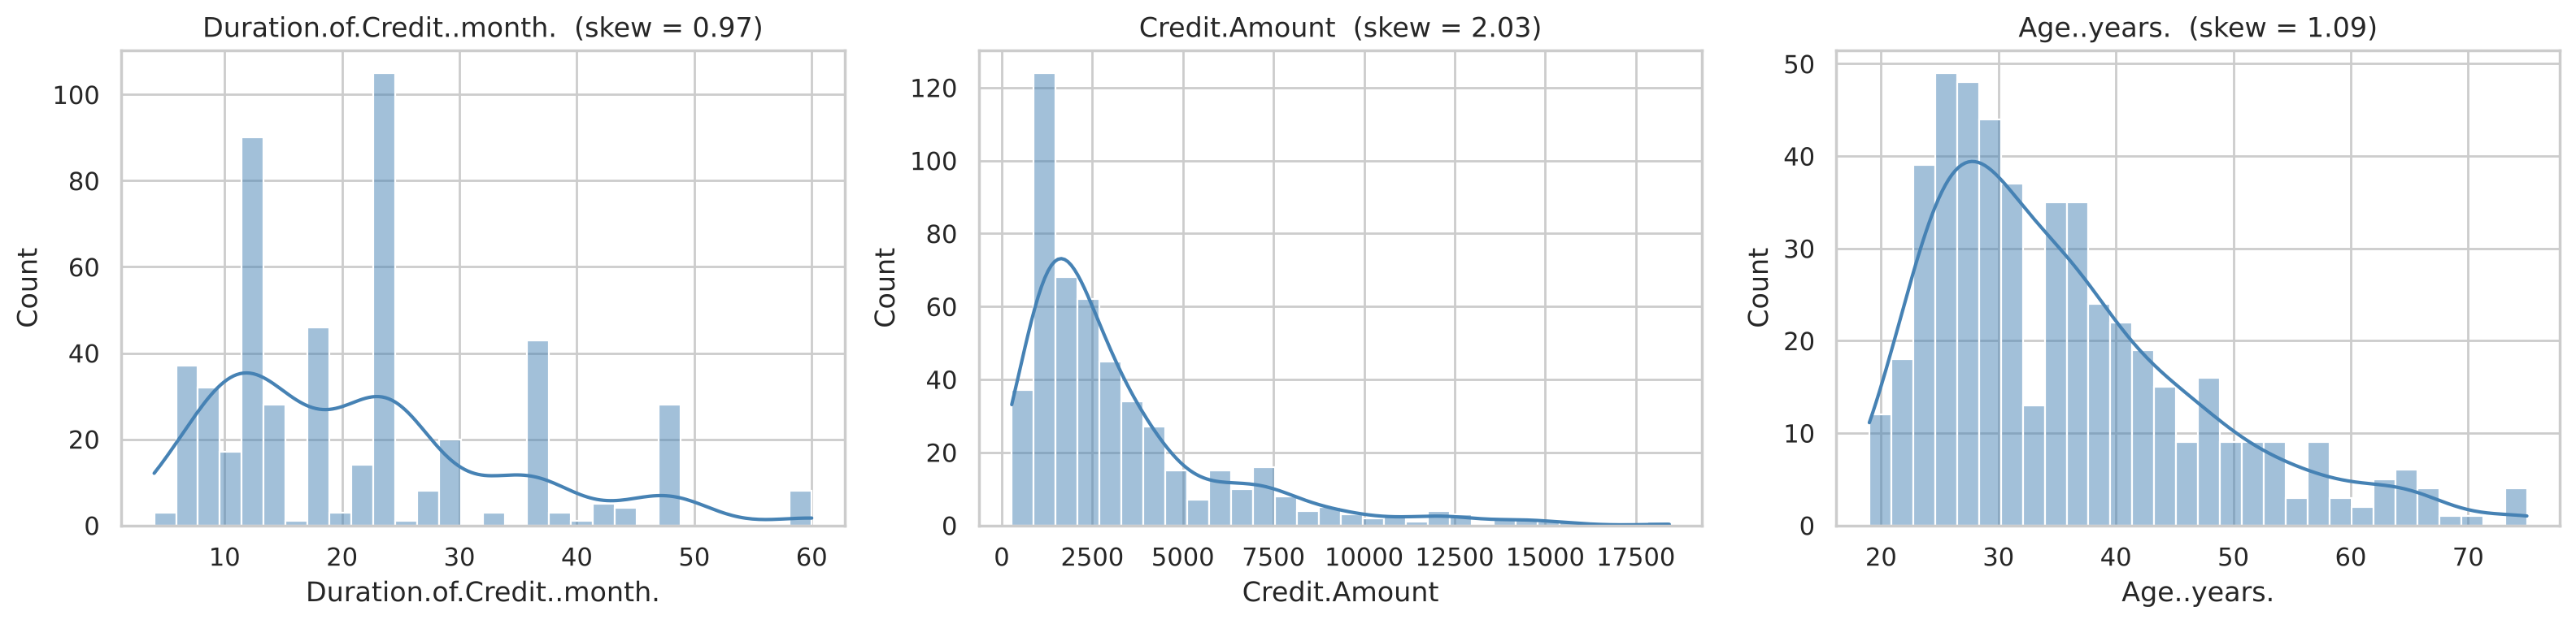

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["Duration.of.Credit..month.", "Credit.Amount", "Age..years."]):
    sns.histplot(df[col], bins=30, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}  (skew = {df[col].skew():.2f})")
plt.tight_layout(); plt.show()

`Credit.Amount` is strongly right-skewed (a few very large loans). In a distance-based method like DBSCAN such a tail would dominate the Euclidean distance, so we apply a **log transformation** to it before scaling.

In [6]:
# Default rate (share of bad borrowers) for every category of the coded variables
cat_cols = [c for c in df.columns if df[c].nunique() <= 5 and c != "Creditability"]
rows = []
for c in cat_cols:
    g = df.groupby(c)["Creditability"].agg(["size", "mean"])
    for code_val, r in g.iterrows():
        rows.append({"variable": c, "code": code_val, "n": int(r["size"]), "bad_rate": round(1 - r["mean"], 2)})
risk_by_cat = pd.DataFrame(rows)
risk_by_cat.pivot(index="variable", columns="code", values="bad_rate")

code,1,2,3,4
variable,,,,
Account.Balance,0.47,0.39,0.14,NaN
Concurrent.Credits,0.44,0.26,NaN,NaN
Duration.in.Current.address,0.22,0.29,0.35,0.28
Foreign.Worker,0.29,0.24,NaN,NaN
Guarantors,0.28,0.36,NaN,NaN
Instalment.per.cent,0.27,0.26,0.23,0.32
Length.of.current.employment,0.36,0.31,0.22,0.24
Most.valuable.available.asset,0.22,0.28,0.28,0.43
No.of.Credits.at.this.Bank,0.30,0.26,NaN,NaN


The default rates already show which variables are financially meaningful: a **negative account balance** (47 % bad vs 14 % for the best category), **past payment problems** (68 % bad), **no savings**, **short employment** and **no property** are clear risk markers, while `Telephone`, `Foreign.Worker`, `No.of.dependents` hardly change the risk.

### 1.3 Encoding and standardization

* **Nominal** variables (`Purpose`, `Sex...Marital.Status`, `Most.valuable.available.asset`, `Type.of.apartment`) have no natural order → **one-hot encoding**.
* **Ordinal / binary** variables already have a meaningful order (1 < 2 < 3 …) → kept as numbers.
* `Credit.Amount` → `log`.
* All features → **StandardScaler** (mean 0, std 1). Without scaling `Credit.Amount` (hundreds–thousands) would completely dominate `Account.Balance` (1–3), and `eps` would be meaningless.

In [7]:
NOMINAL = ["Purpose", "Sex...Marital.Status", "Most.valuable.available.asset", "Type.of.apartment"]

def preprocess(data, features):
    X = data[features].copy()
    if "Credit.Amount" in features:
        X["Credit.Amount"] = np.log(X["Credit.Amount"])
    X = pd.get_dummies(X, columns=[c for c in NOMINAL if c in features], dtype=float)
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
    return X_scaled

ALL_FEATURES = [c for c in df.columns if c != "Creditability"]
X_all = preprocess(df, ALL_FEATURES)
print("Encoded + standardized matrix (all features):", X_all.shape)
X_all.describe().loc[["mean", "std"]].round(2).iloc[:, :8]

Encoded + standardized matrix (all features): (500, 29)


,Account.Balance,Duration.of.Credit..month.,Payment.Status.of.Previous.Credit,Credit.Amount,Value.Savings.Stocks,Length.of.current.employment,Instalment.per.cent,Guarantors
mean,-0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 2. Parameter selection

DBSCAN has two parameters:

* **`min_samples`** — how many points (including the point itself) must lie inside the `eps`-radius for a point to be a **core point**. It is the *minimum size of a dense group* we are willing to call a segment.
* **`eps`** — the radius of the neighbourhood. Points closer than `eps` to a core point are density-reachable and join its cluster; points that are not reachable from any core point are **noise (label −1)**.

Standard procedure: fix `min_samples`, draw the **k-distance graph** (distance of every point to its k-th nearest neighbour, k = `min_samples`, sorted) and take `eps` at the **"elbow"**, where distances start to grow sharply — points to the right of the elbow are in sparse regions (future noise).

### 2.1 First attempt: all 28 encoded features

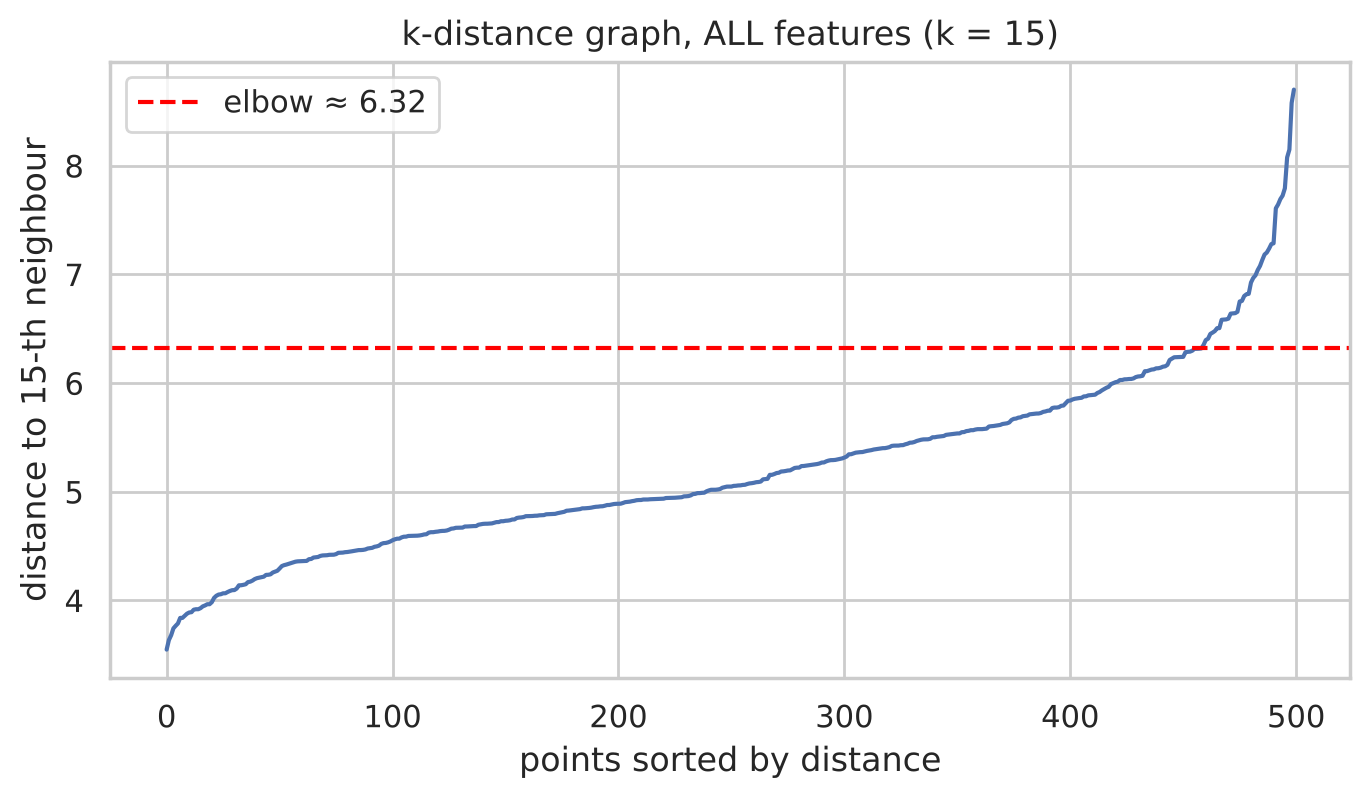

  eps | clusters | noise | silhouette | cluster sizes
 4.50 |        1 | 52.4% |        nan | [238]
 5.00 |        1 | 25.8% |        nan | [371]
 6.32 |        1 |  2.8% |        nan | [486]
 5.50 |        1 |  8.8% |        nan | [456]
 6.00 |        1 |  4.0% |        nan | [480]


In [8]:
def k_distance(X, k):
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    dist, _ = nn.kneighbors(X)
    return np.sort(dist[:, -1])

def find_knee(d):
    # point of maximum distance from the straight line joining the first and last point of the curve
    x = np.arange(len(d)); p1 = np.array([0, d[0]]); p2 = np.array([len(d) - 1, d[-1]])
    line = (p2 - p1) / np.linalg.norm(p2 - p1)
    vec = np.column_stack([x, d]) - p1
    dist = np.abs(vec[:, 0] * line[1] - vec[:, 1] * line[0])
    return int(np.argmax(dist))

def summarize(labels, X):
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = np.mean(labels == -1)
    mask = labels != -1
    sil = silhouette_score(X[mask], labels[mask]) if n_clusters > 1 else np.nan
    sizes = sorted(np.bincount(labels[mask]).tolist(), reverse=True) if n_clusters > 0 else []
    return n_clusters, noise, sil, sizes

k = 15
d_all = k_distance(X_all.values, k)
knee = find_knee(d_all)
plt.figure(figsize=(8, 4))
plt.plot(d_all); plt.axhline(d_all[knee], ls="--", c="red", label=f"elbow ≈ {d_all[knee]:.2f}")
plt.title(f"k-distance graph, ALL features (k = {k})"); plt.xlabel("points sorted by distance"); plt.ylabel(f"distance to {k}-th neighbour")
plt.legend(); plt.show()

print(f"{'eps':>5} | clusters | noise | silhouette | cluster sizes")
for eps in [4.5, 5.0, d_all[knee], 5.5, 6.0]:
    lab = DBSCAN(eps=eps, min_samples=k).fit_predict(X_all)
    n, noise, sil, sizes = summarize(lab, X_all.values)
    print(f"{eps:5.2f} | {n:8d} | {noise:5.1%} | {sil:10.3f} | {sizes}")

With all 28 dimensions the result is poor: the k-distance curve is smooth (no clear density gaps) and for any reasonable `eps` DBSCAN produces **one giant cluster (≈ 80–95 % of customers) plus noise**. This is the **curse of dimensionality**: in 28 dimensions all pairwise distances become similar, so "dense" and "sparse" regions are hard to distinguish. Many of these dimensions (telephone, foreign worker, number of dependents, years at the address, purpose dummies, sex dummies) are almost unrelated to the financial profile (see the default-rate table in 1.2) and only add noise to the distance.

### 2.2 Feature selection: the financial profile

We therefore cluster on the variables that describe the **financial profile** of a customer — exactly the variables the task asks to analyse (credit amount, credit history, loan duration, employment, income proxies):

| Group | Features |
|---|---|
| Loan | `Credit.Amount` (log), `Duration.of.Credit..month.` |
| Credit history | `Payment.Status.of.Previous.Credit` |
| Liquidity / income proxies | `Account.Balance`, `Value.Savings.Stocks`, `Length.of.current.employment` |
| Wealth / stability | `Most.valuable.available.asset` (one-hot), `Type.of.apartment` (one-hot) |
| Demographics | `Age..years.` |

All other variables are kept for **profiling** the clusters afterwards (section 4).

In [9]:
CLUSTER_FEATURES = ["Account.Balance", "Duration.of.Credit..month.", "Payment.Status.of.Previous.Credit",
                    "Credit.Amount", "Value.Savings.Stocks", "Length.of.current.employment",
                    "Most.valuable.available.asset", "Age..years.", "Type.of.apartment"]
X = preprocess(df, CLUSTER_FEATURES)
print("Clustering matrix:", X.shape)
print(list(X.columns))

Clustering matrix: (500, 14)
['Account.Balance', 'Duration.of.Credit..month.', 'Payment.Status.of.Previous.Credit', 'Credit.Amount', 'Value.Savings.Stocks', 'Length.of.current.employment', 'Age..years.', 'Most.valuable.available.asset_1', 'Most.valuable.available.asset_2', 'Most.valuable.available.asset_3', 'Most.valuable.available.asset_4', 'Type.of.apartment_1', 'Type.of.apartment_2', 'Type.of.apartment_3']


### 2.3 Choosing `min_samples`

Common rules of thumb: `min_samples ≥ D + 1` and `min_samples ≈ 2·D` for noisy data (D = 14 dimensions → 15 … 28).
`2·D = 28` would be too strict for only 500 customers (a segment would need ≥ 28 almost identical clients within a small radius), so we take the lower bound **`min_samples = 15` (= D + 1)**:

* 15 customers = 3 % of the portfolio — a segment smaller than that is not useful for a bank's credit policy;
* it is large enough to make the density estimate robust (single random coincidences do not create clusters);
* below we check that nearby values (12 and 18) give the same picture.

### 2.4 Choosing `eps` with the k-distance graph

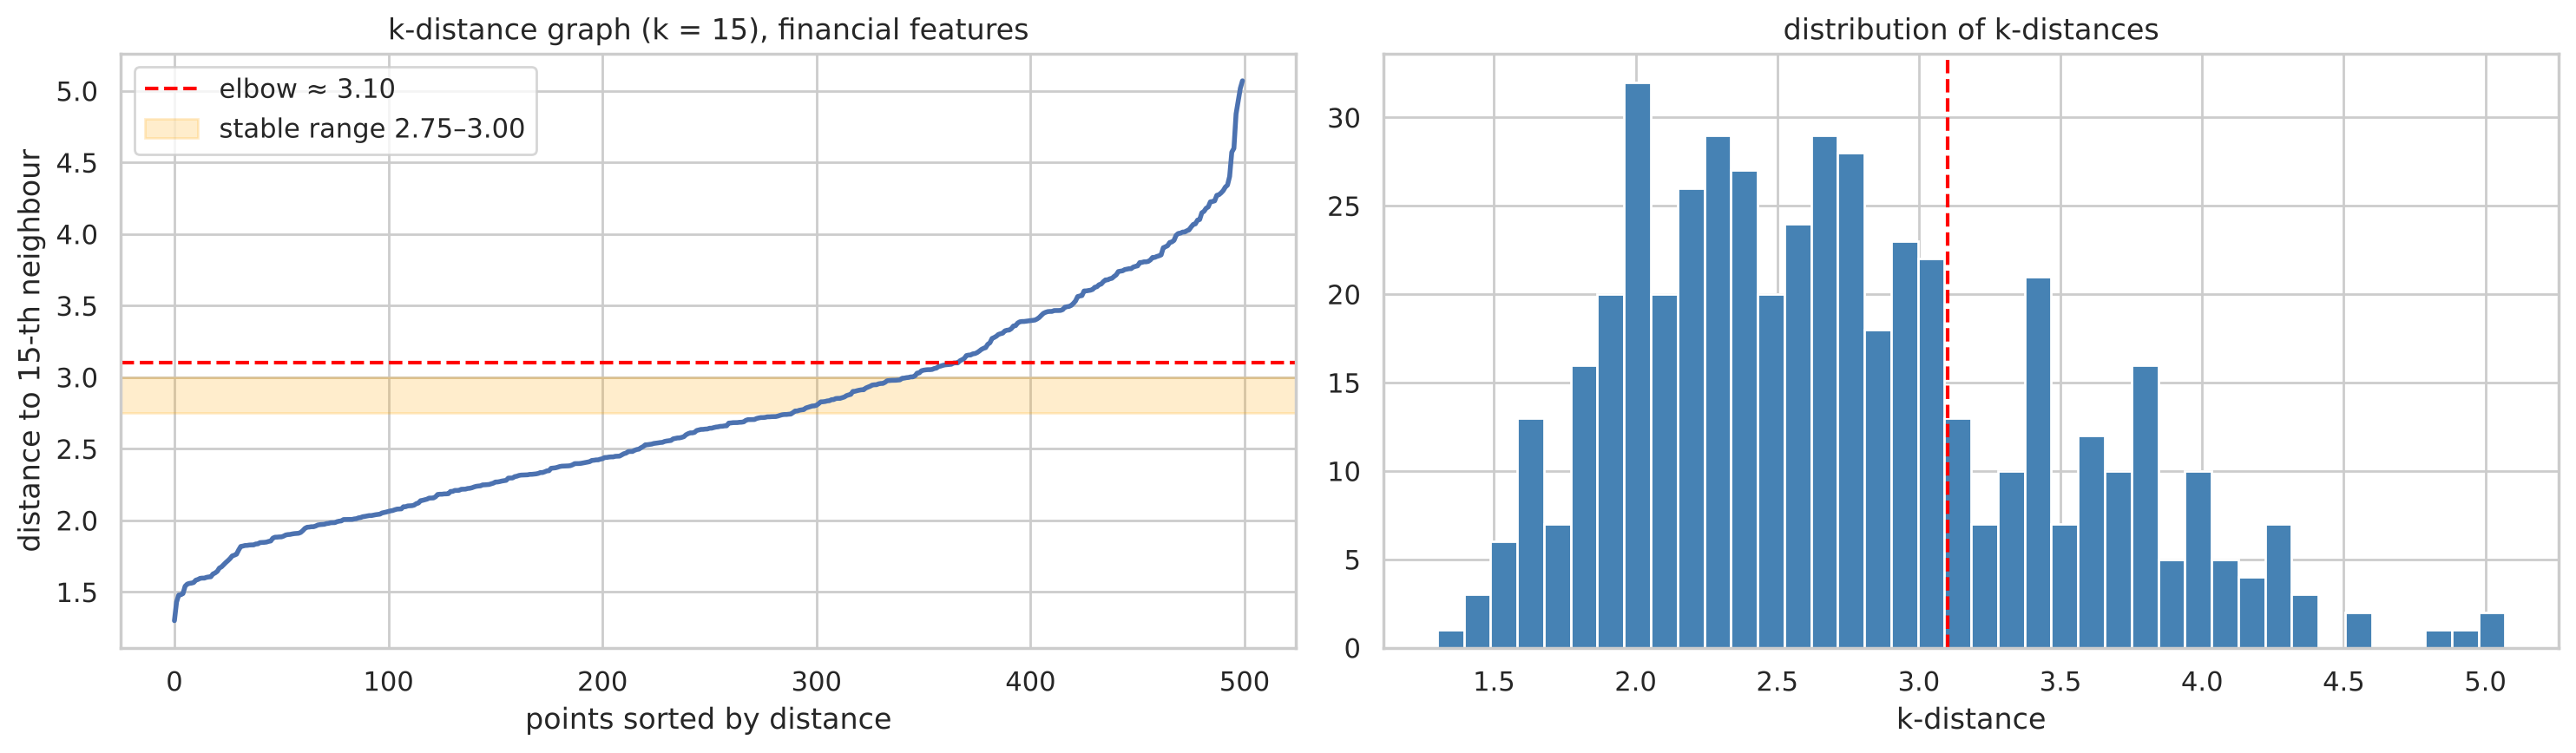

Elbow of the curve: eps ≈ 3.10


In [10]:
MIN_SAMPLES = 15
d = k_distance(X.values, MIN_SAMPLES)
knee = find_knee(d)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(d, lw=2)
ax[0].axhline(d[knee], ls="--", c="red", label=f"elbow ≈ {d[knee]:.2f}")
ax[0].axhspan(2.75, 3.0, color="orange", alpha=0.2, label="stable range 2.75–3.00")
ax[0].set_title(f"k-distance graph (k = {MIN_SAMPLES}), financial features")
ax[0].set_xlabel("points sorted by distance"); ax[0].set_ylabel(f"distance to {MIN_SAMPLES}-th neighbour"); ax[0].legend()
ax[1].hist(d, bins=40, color="steelblue"); ax[1].axvline(d[knee], c="red", ls="--")
ax[1].set_title("distribution of k-distances"); ax[1].set_xlabel("k-distance")
plt.tight_layout(); plt.show()
print(f"Elbow of the curve: eps ≈ {d[knee]:.2f}")

### 2.5 Grid search and stability check

The elbow gives a starting region; to choose a precise value we run DBSCAN on a grid of (`eps`, `min_samples`) and look at:
number of clusters, share of noise and the silhouette score of the clustered points. A good parameter choice lies on a **plateau** — a range where the result does not change when `eps` changes slightly.

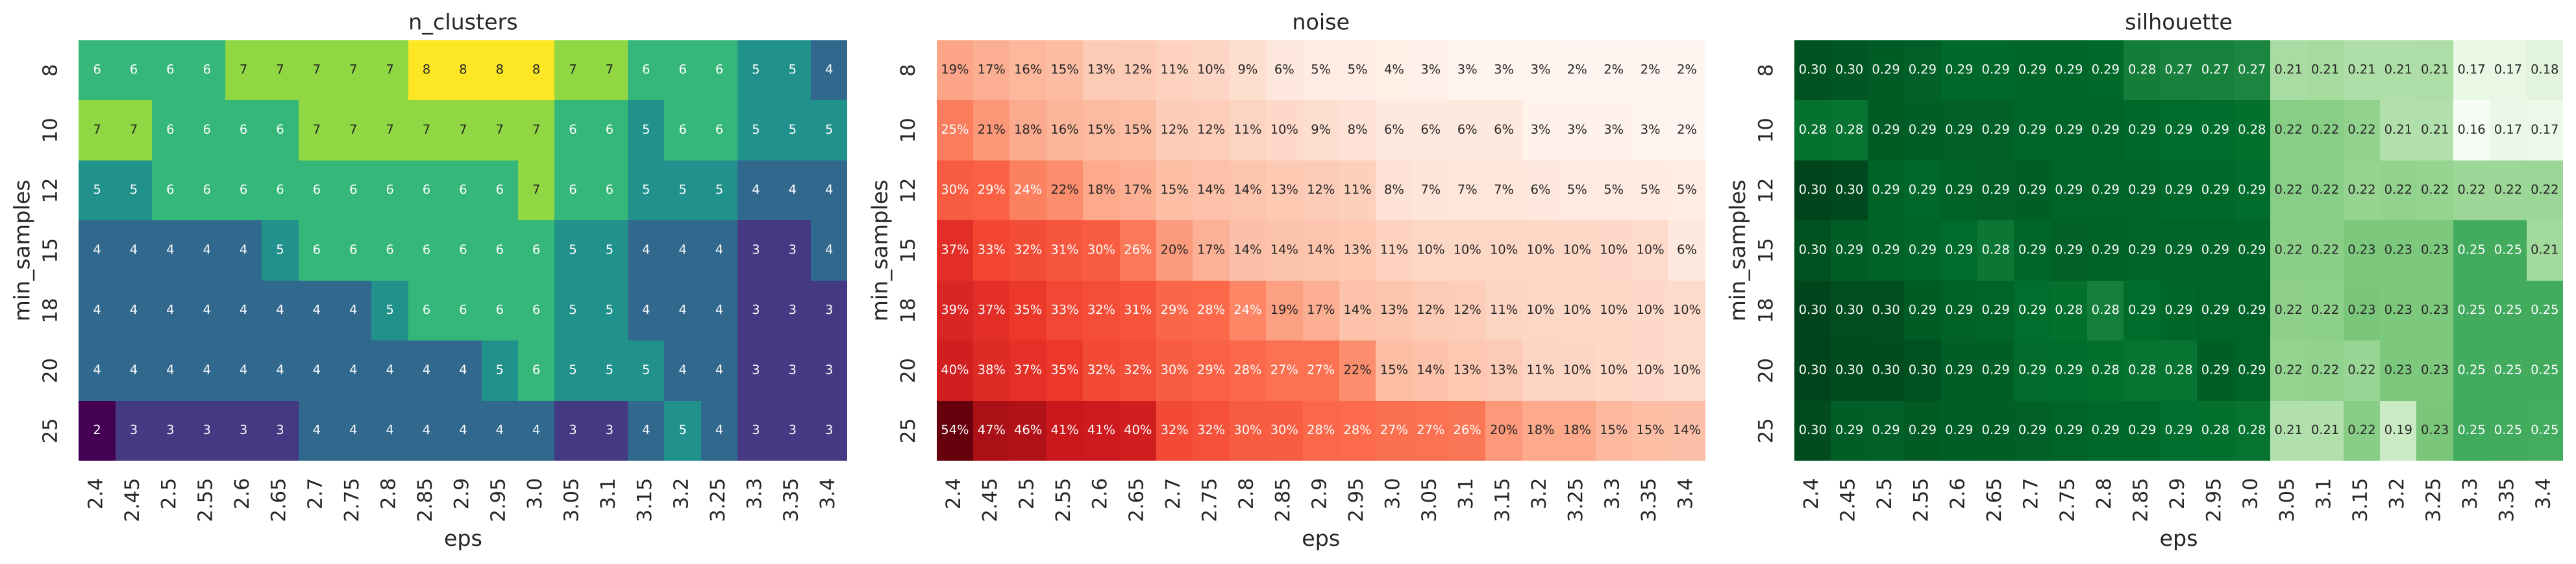

In [11]:
eps_grid = np.round(np.arange(2.40, 3.41, 0.05), 2)
ms_grid = [8, 10, 12, 15, 18, 20, 25]
res = []
for ms in ms_grid:
    for eps in eps_grid:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        n, noise, sil, sizes = summarize(lab, X.values)
        res.append({"min_samples": ms, "eps": eps, "n_clusters": n, "noise": noise, "silhouette": sil})
grid = pd.DataFrame(res)

fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
for ax, metric, fmt, cmap in zip(axes, ["n_clusters", "noise", "silhouette"], ["d", ".0%", ".2f"], ["viridis", "Reds", "Greens"]):
    pv = grid.pivot(index="min_samples", columns="eps", values=metric)
    sns.heatmap(pv, annot=True, fmt=fmt, cmap=cmap, ax=ax, cbar=False, annot_kws={"size": 7})
    ax.set_title(metric)
plt.tight_layout(); plt.show()

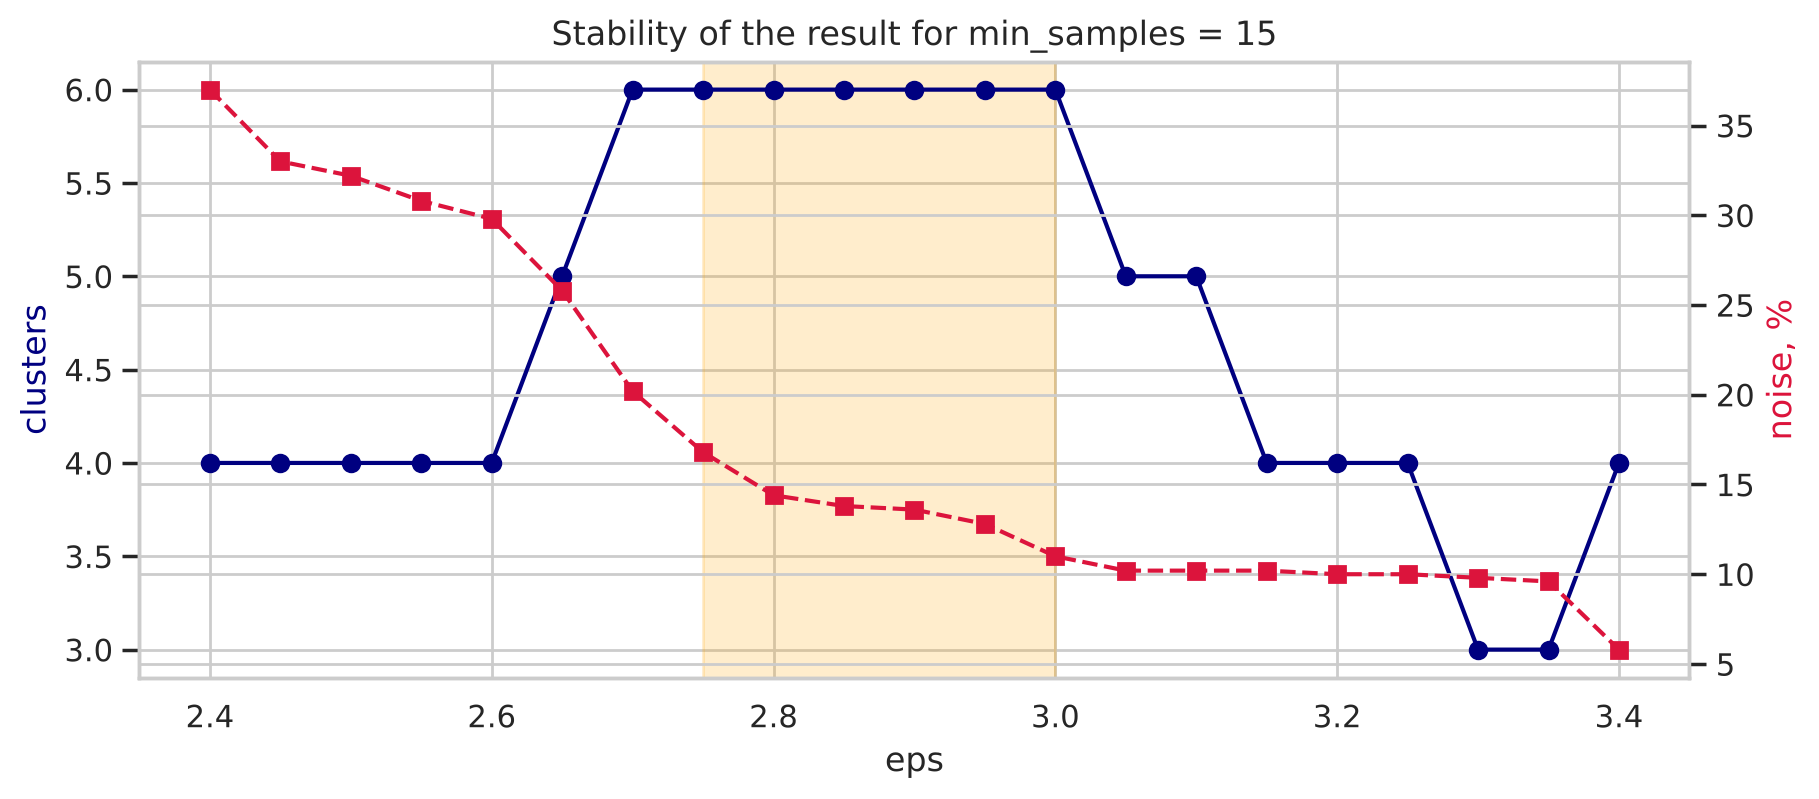

eps,2.40,2.45,2.50,2.55,2.60,2.65,2.70,2.75,2.80,2.85,2.90,2.95,3.00,3.05,3.10,3.15,3.20,3.25,3.30,3.35,3.40
n_clusters,4.000,4.000,4.000,4.000,4.000,5.000,6.000,6.000,6.000,6.000,6.000,6.000,6.000,5.000,5.000,4.000,4.000,4.000,3.000,3.000,4.000
noise,0.370,0.330,0.322,0.308,0.298,0.258,0.202,0.168,0.144,0.138,0.136,0.128,0.110,0.102,0.102,0.102,0.100,0.100,0.098,0.096,0.058
silhouette,0.299,0.293,0.292,0.290,0.287,0.280,0.290,0.292,0.291,0.291,0.291,0.290,0.289,0.223,0.223,0.229,0.229,0.229,0.250,0.250,0.213


In [12]:
stab = grid[grid.min_samples == MIN_SAMPLES].set_index("eps")
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(stab.index, stab.n_clusters, "o-", c="navy", label="number of clusters"); ax1.set_ylabel("clusters", color="navy")
ax2 = ax1.twinx(); ax2.plot(stab.index, stab.noise * 100, "s--", c="crimson", label="noise %"); ax2.set_ylabel("noise, %", color="crimson")
ax1.axvspan(2.75, 3.0, color="orange", alpha=0.2); ax1.set_xlabel("eps")
ax1.set_title(f"Stability of the result for min_samples = {MIN_SAMPLES}")
plt.show()
stab[["n_clusters", "noise", "silhouette"]].round(3).T

### 2.6 Automatic choice of the optimal `eps`

Rule used (written as code so that it is reproducible):
1. keep only *acceptable* solutions: at least 2 clusters and at most 15 % noise;
2. take the number of clusters of the best-silhouette acceptable solution;
3. the **plateau** = all `eps` values that give this same number of clusters;
4. the optimal `eps` = the **middle of the plateau** (the most stable value: a small change of `eps` in either direction does not change the result).

In [13]:
rows = []
for eps in np.round(np.arange(2.40, 3.41, 0.05), 2):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    n, noise, sil, _ = summarize(lab, X.values)
    rows.append({"eps": eps, "n_clusters": n, "noise": noise, "silhouette": sil})
cand = pd.DataFrame(rows)

ok = cand[(cand.n_clusters >= 2) & (cand.noise <= 0.15)]
n_best = int(ok.loc[ok.silhouette.idxmax(), "n_clusters"])
plateau = cand[cand.n_clusters == n_best]
EPS_OPT = float(plateau.eps.iloc[len(plateau) // 2])

print(f"Stable plateau: eps from {plateau.eps.min()} to {plateau.eps.max()} -> always {n_best} clusters")
print(f"OPTIMAL eps = {EPS_OPT}  (middle of the plateau), min_samples = {MIN_SAMPLES}")
plateau.round(3)

Stable plateau: eps from 2.7 to 3.0 -> always 6 clusters
OPTIMAL eps = 2.85  (middle of the plateau), min_samples = 15


,eps,n_clusters,noise,silhouette
6,2.70,6,0.202,0.290
7,2.75,6,0.168,0.292
8,2.80,6,0.144,0.291
9,2.85,6,0.138,0.291
10,2.90,6,0.136,0.291
11,2.95,6,0.128,0.290
12,3.00,6,0.110,0.289


### 2.7 What DBSCAN produces for different `eps` (PCA view)

Order of operations in every panel: **(1)** DBSCAN is run on the 14-dimensional standardized matrix `X`; **(2)** only afterwards the points are drawn on a 2-D PCA projection and coloured with the labels DBSCAN returned. PCA is used **only for drawing**, it does not influence the clusters.

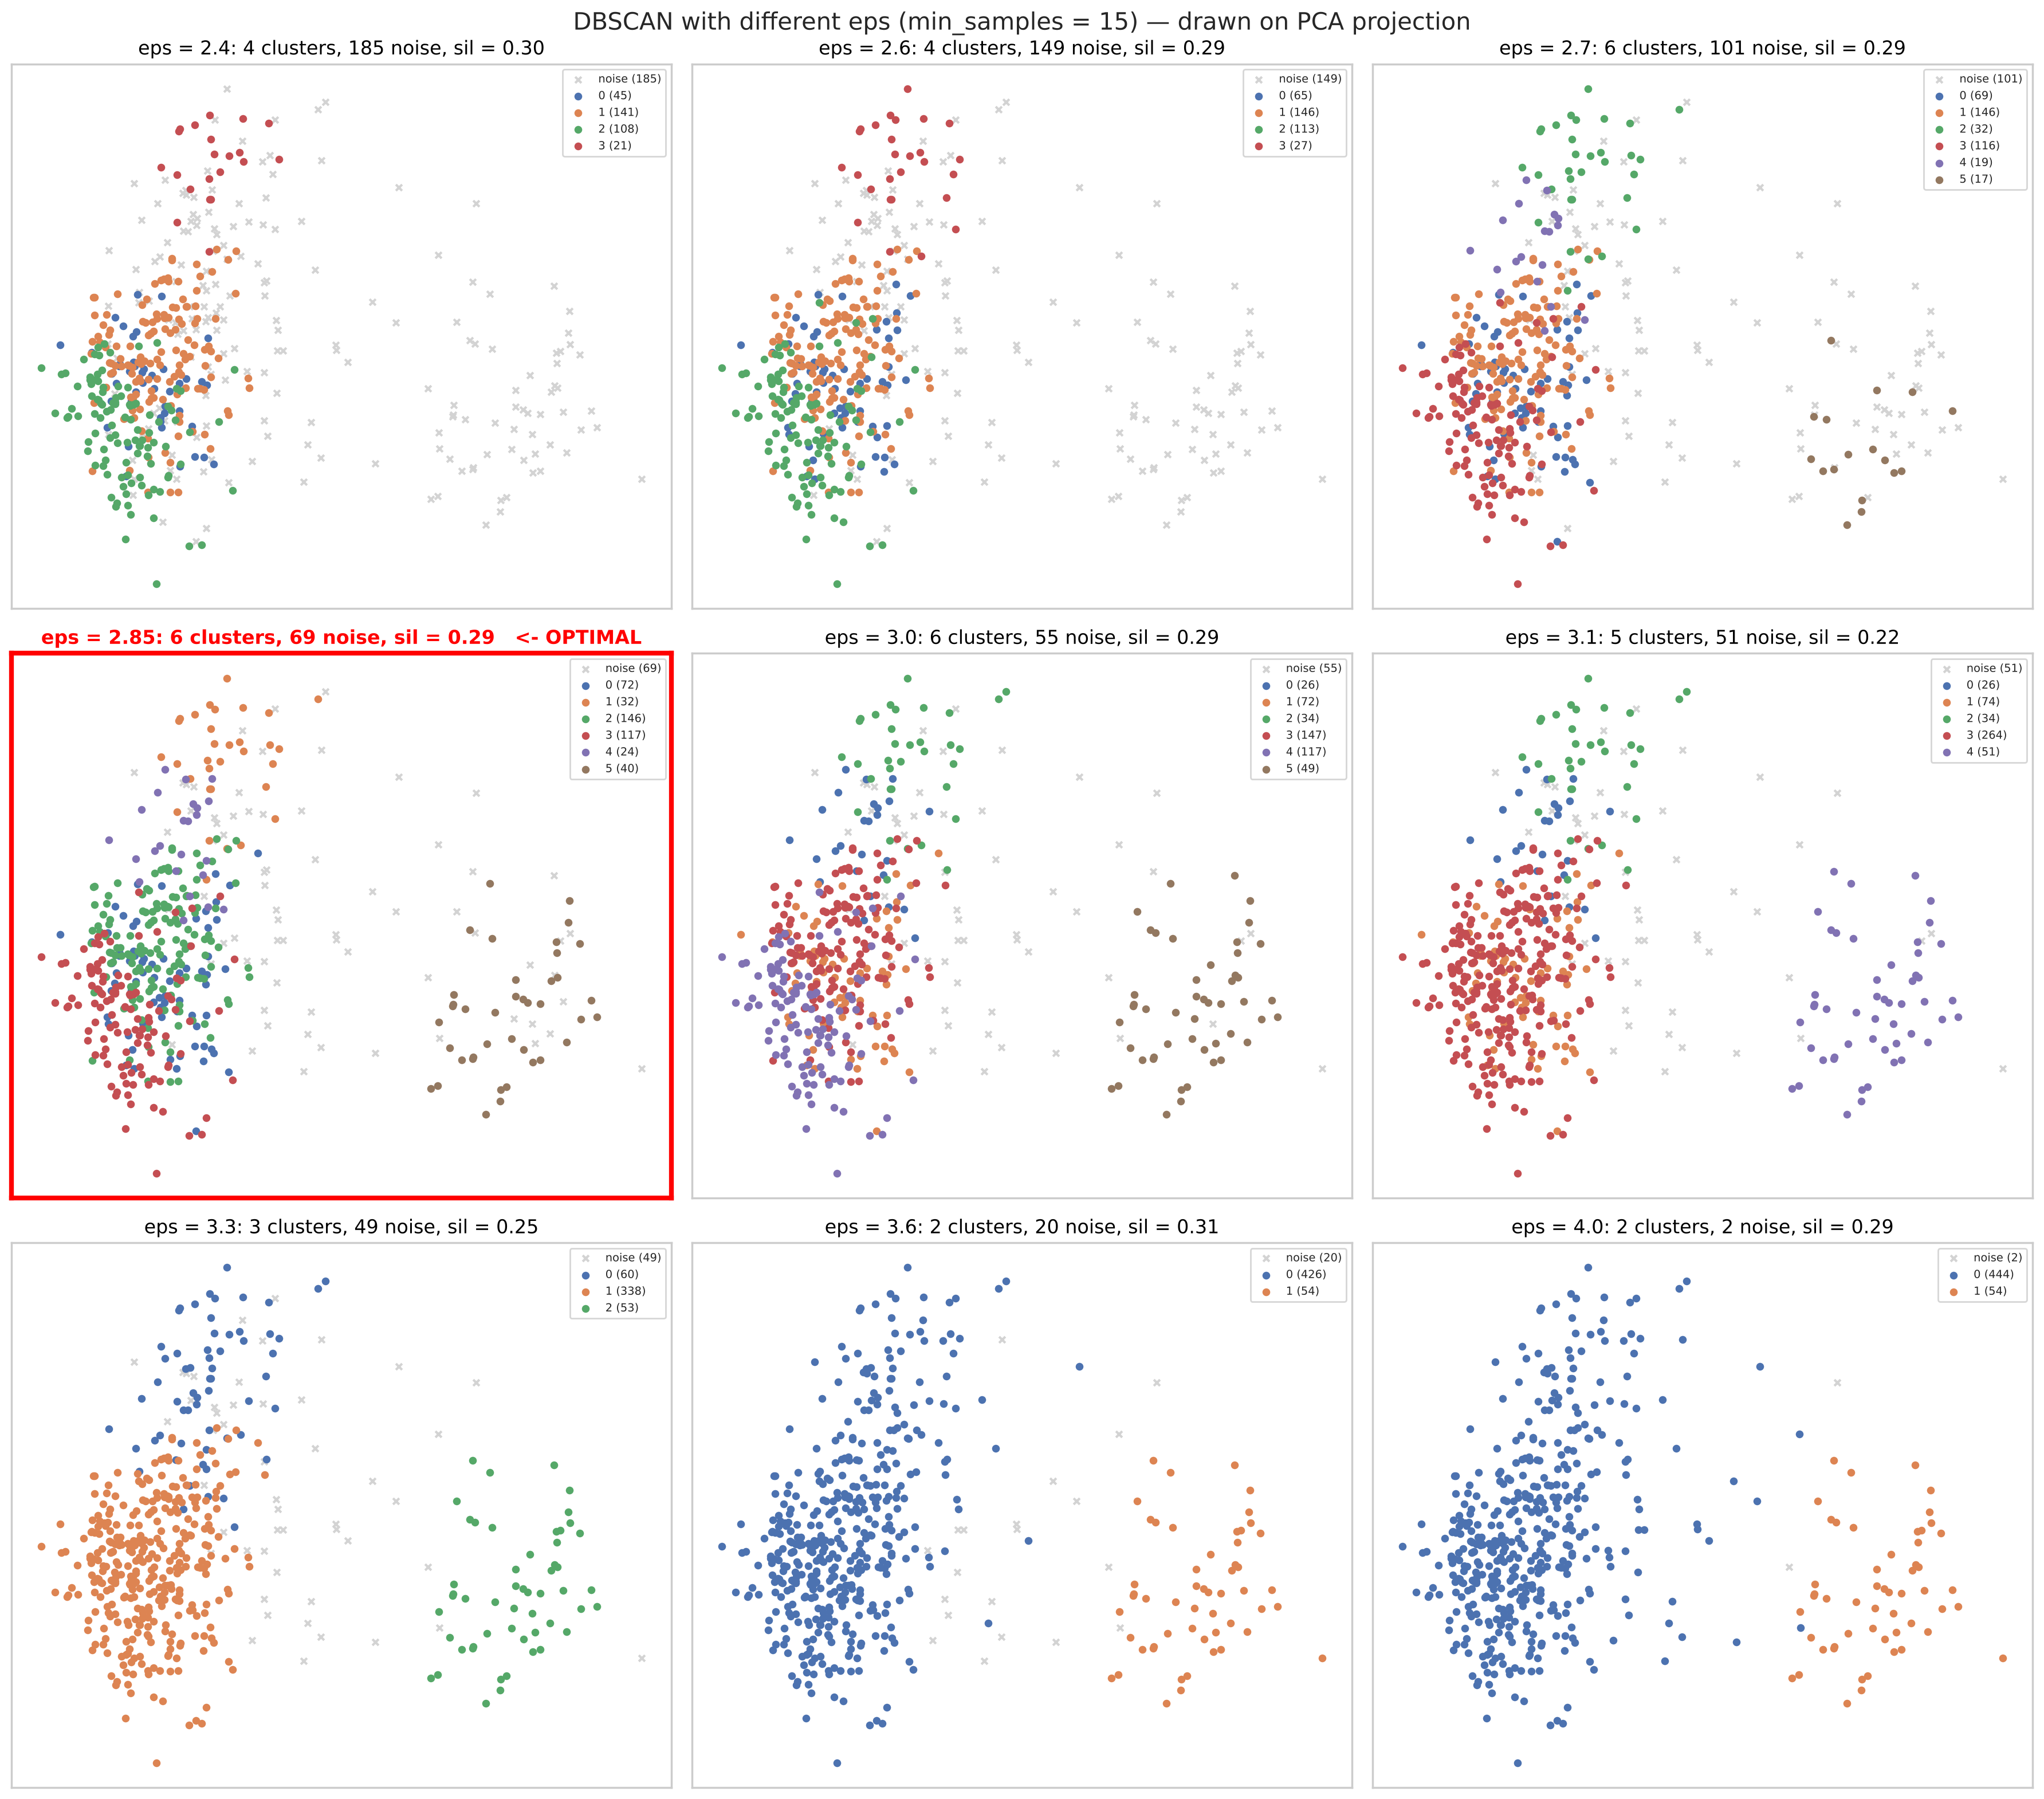

In [14]:
def plot_eps_grid(proj, proj_name, eps_list, X_cluster=X, min_samples=MIN_SAMPLES, eps_opt=None):
    # DBSCAN is fitted on X_cluster; proj is only the 2-D picture used to draw the result
    fig, axes = plt.subplots(3, 3, figsize=(18, 16))
    for ax, eps in zip(axes.ravel(), eps_list):
        lab = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_cluster)   # step 1: cluster
        n, noise, sil, _ = summarize(lab, np.asarray(X_cluster))
        noise_m = lab == -1                                                    # step 2: draw
        ax.scatter(proj[noise_m, 0], proj[noise_m, 1], c="lightgrey", marker="x", s=15, label=f"noise ({noise_m.sum()})")
        for c in sorted(set(lab) - {-1}):
            m = lab == c
            ax.scatter(proj[m, 0], proj[m, 1], s=15, label=f"{c} ({m.sum()})")
        best = eps_opt is not None and abs(eps - eps_opt) < 1e-9
        ax.set_title(f"eps = {eps}: {n} clusters, {noise_m.sum()} noise" + (f", sil = {sil:.2f}" if n > 1 else "")
                     + ("   <- OPTIMAL" if best else ""), color="red" if best else "black",
                     fontweight="bold" if best else "normal")
        if best:
            for sp in ax.spines.values(): sp.set_edgecolor("red"); sp.set_linewidth(3)
        ax.legend(fontsize=7, loc="upper right"); ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f"DBSCAN with different eps (min_samples = {min_samples}) — drawn on {proj_name}", fontsize=15)
    plt.tight_layout(); plt.show()

EPS_SHOW = [2.4, 2.6, 2.7, 2.85, 3.0, 3.1, 3.3, 3.6, 4.0]
P_grid = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)   # 2-D picture only
plot_eps_grid(P_grid, "PCA projection", EPS_SHOW, eps_opt=EPS_OPT)

**How to read the grid.** Every point is a customer; grey crosses are noise, colours are clusters (sizes in the legend). Note that DBSCAN numbers clusters in the order it discovers them, so the *same* group can get a different colour/number in different panels — compare the sizes, not the colours.

* **eps = 2.4 and 2.6 — eps too small:** only 4 clusters and 150–185 noise points (≈ a third of all customers). The whole group on the right (customers with no property who live for free) is grey: the group exists, but with such a small radius none of its points has 15 neighbours, so it is lost in the noise.
* **eps = 2.7:** the 6th cluster appears on the right (still small, 17 customers).
* **eps = 2.85 — optimal (red frame):** 6 clusters, 69 noise points (13.8 %), silhouette 0.29. The no-property group on the right is a full cluster (40), the young renters are at the top, the three homeowner groups at the bottom-left, and the noise is scattered between and around the groups.
* **eps = 3.0:** still 6 clusters with less noise — the end of the plateau.
* **eps = 3.1 — merging starts:** a cluster of **264** appears = the two largest homeowner groups (146 + 117) glued together through border points, although their risk differs (25 % vs 21 % bad).
* **eps = 3.3 → 4.0 — eps too large:** 3 and then 2 clusters ("everyone else" vs the no-property group); the segmentation loses its meaning.

**Why the homeowner groups overlap in this picture.** PCA is linear and its first two components explain only about one third of the variance. The homeowner groups differ mainly by the *type of asset* (real estate / car / savings), which is hardly represented in PC1–PC2, so they overlap on the plane although they are separated in the 14-dimensional space where DBSCAN works. A non-linear view (t-SNE / UMAP) of the same labels is given in sections 8–9.

### 2.8 Selected parameters: `eps = 2.85`, `min_samples = 15` — why they suit this dataset

**What the graphs show**

* The k-distance curve rises slowly up to ≈ 3.0 and then bends sharply at **≈ 3.1** (the elbow). Customers to the right of the elbow (k-distance > 3.1, roughly the last 25–30 %) live in sparse regions.
* For `min_samples = 15` the result is a **plateau between eps = 2.70 and 3.00**: always **6 clusters**, silhouette ≈ 0.29, noise falls smoothly from 20 % to 11 %. The cluster structure does not depend on the exact value — a sign that it reflects real density in the data, not a random parameter choice.
* The same 6 clusters appear for `min_samples` = 12 and 18 (heatmap), so the result is also robust to `min_samples`.

**Why `eps = 2.85` (the middle of the plateau, just below the elbow)**

* **eps too small (< 2.65):** dense groups break up and 26–37 % of all customers become noise — we would flag a third of the portfolio as "atypical", which is useless for a bank.
* **eps too large (≥ 3.05):** *chaining* starts — DBSCAN joins the two largest homeowner groups (clusters 2 and 3 → one cluster of 264) through a bridge of border points, and at ≥ 3.4 everything collapses into a few large clusters. Different risk profiles (21 % vs 25 % default rate) would be mixed.
* **2.85** sits in the middle of the stable range, slightly to the left of the elbow, so the dense cores are kept separate while only genuinely isolated customers (~14 %) are marked as noise. 14 % noise is a reasonable "manual review" share for a loan portfolio.

**How the parameters influence the result**

| change | effect |
|---|---|
| ↑ `eps` | larger neighbourhoods → fewer, bigger clusters, less noise, risk of merging different segments |
| ↓ `eps` | clusters split / shrink, more customers labelled noise |
| ↑ `min_samples` | stricter definition of "dense" → only big, homogeneous segments survive, more noise |
| ↓ `min_samples` | tiny groups of 4–5 customers become clusters → many unstable micro-segments |

## 3. Clustering implementation

In [15]:
EPS = EPS_OPT          # = 2.85, chosen in section 2.6
dbscan = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)
labels = dbscan.fit_predict(X)

n_clusters, noise_share, sil, sizes = summarize(labels, X.values)
core_mask = np.zeros(len(labels), dtype=bool); core_mask[dbscan.core_sample_indices_] = True
print(f"eps = {EPS}, min_samples = {MIN_SAMPLES}")
print(f"Clusters found: {n_clusters}")
print(f"Noise points:   {(labels == -1).sum()} ({noise_share:.1%})")
print(f"Core points: {core_mask.sum()},  border points: {((labels != -1) & ~core_mask).sum()}")
print(f"Silhouette (without noise): {sil:.3f}")
print(f"Davies-Bouldin (without noise): {davies_bouldin_score(X[labels != -1], labels[labels != -1]):.3f}")

df_res = df.copy()
df_res["Cluster"] = labels
df_res["Bad"] = 1 - df_res["Creditability"]
df_res["Cluster"].value_counts().sort_index().rename("customers").to_frame().T

eps = 2.85, min_samples = 15
Clusters found: 6
Noise points:   69 (13.8%)
Core points: 309,  border points: 122
Silhouette (without noise): 0.291
Davies-Bouldin (without noise): 1.354


Cluster,-1,0,1,2,3,4,5
customers,69,72,32,146,117,24,40


### 3.1 Noise points — who are they?

DBSCAN labels as **noise (−1)** the customers that do not belong to any dense region: they have no 15 similar customers within distance `eps`. In credit scoring these are **atypical / unusual applications**: an unusual combination of loan size, duration, assets and history. They are not "errors" — they are exactly the cases a standard scorecard is least reliable for.

In [16]:
num_cols = ["Credit.Amount", "Duration.of.Credit..month.", "Age..years.", "Account.Balance",
            "Payment.Status.of.Previous.Credit", "Value.Savings.Stocks", "Length.of.current.employment",
            "Instalment.per.cent", "Guarantors", "Bad"]
cmp = pd.DataFrame({
    "Noise (−1)": df_res[df_res.Cluster == -1][num_cols].mean(),
    "Clustered customers": df_res[df_res.Cluster != -1][num_cols].mean(),
    "All customers": df_res[num_cols].mean()}).round(2)
cmp

,Noise (−1),Clustered customers,All customers
Credit.Amount,5184.01,2931.21,3242.10
Duration.of.Credit..month.,26.42,20.77,21.55
Age..years.,37.45,35.14,35.46
Account.Balance,2.01,2.28,2.25
Payment.Status.of.Previous.Credit,2.28,2.35,2.34
Value.Savings.Stocks,2.28,1.81,1.87
Length.of.current.employment,2.46,2.45,2.45
Instalment.per.cent,2.94,3.00,2.99
Guarantors,1.16,1.08,1.09
Bad,0.39,0.27,0.29


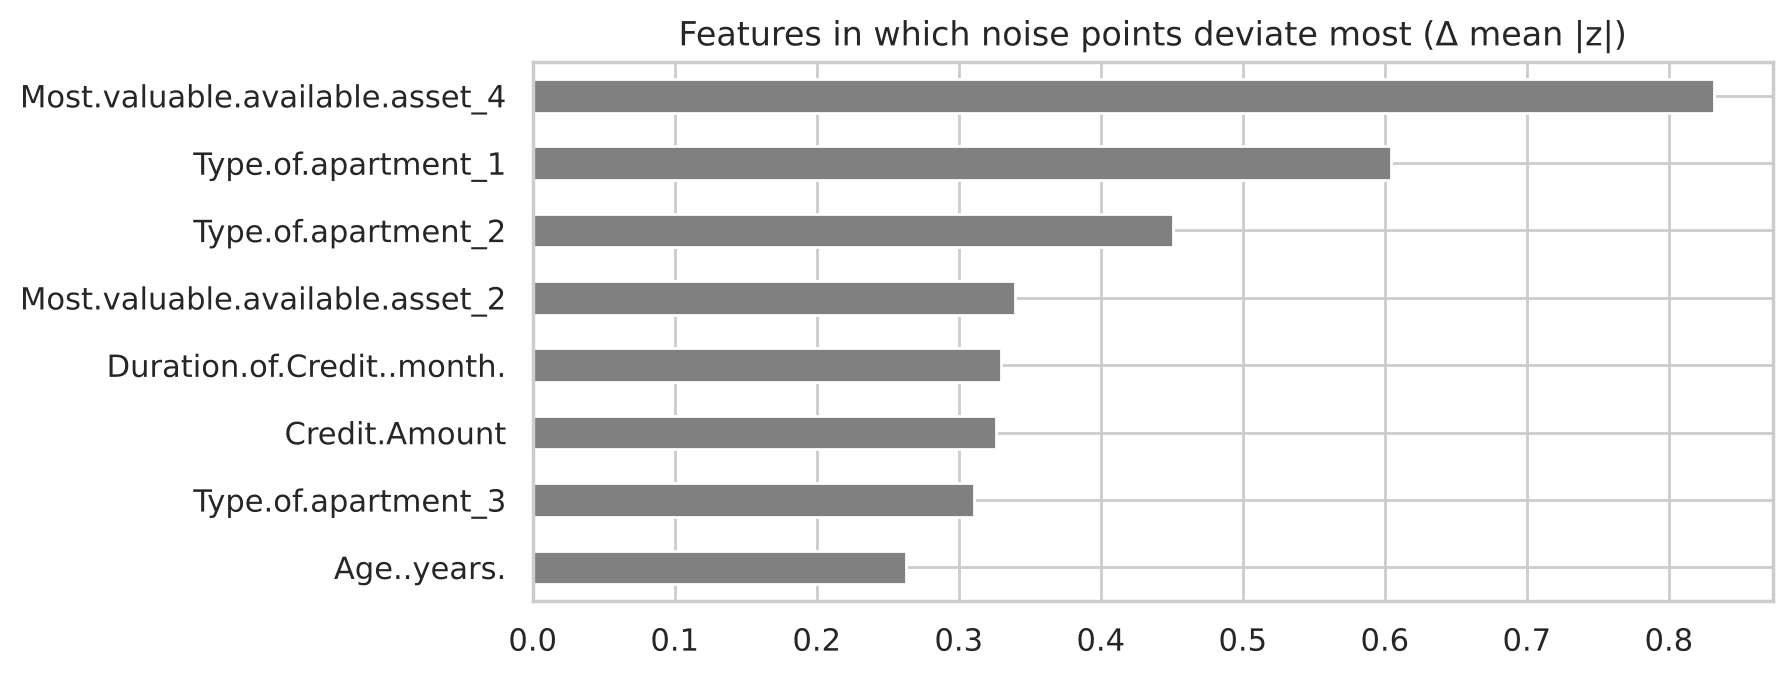

Type.of.apartment,1,2,3,All
Most.valuable.available.asset,,,,
1,3,0,0,3
2,24,2,1,27
3,2,1,0,3
4,5,17,14,36
All,34,20,15,69


In [17]:
# Which features make noise points unusual? -> mean |z-score| of noise vs clustered points
z_noise = X[labels == -1].abs().mean()
z_clust = X[labels != -1].abs().mean()
outl = (z_noise - z_clust).sort_values(ascending=False).head(8)
outl.plot.barh(figsize=(8, 3.5), color="grey"); plt.gca().invert_yaxis()
plt.title("Features in which noise points deviate most (Δ mean |z|)"); plt.show()

# housing x asset combinations of the noise points
pd.crosstab(df_res[df_res.Cluster == -1]["Most.valuable.available.asset"],
            df_res[df_res.Cluster == -1]["Type.of.apartment"], margins=True)

In [18]:
# the 5 most extreme noise customers (largest distance to their 15th neighbour)
kd = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1]
df_res["k_dist"] = kd
df_res[df_res.Cluster == -1].sort_values("k_dist", ascending=False).head(5)[
    ["Credit.Amount", "Duration.of.Credit..month.", "Age..years.", "Account.Balance", "Payment.Status.of.Previous.Credit",
     "Value.Savings.Stocks", "Most.valuable.available.asset", "Type.of.apartment", "Creditability", "k_dist"]]

,Credit.Amount,Duration.of.Credit..month.,Age..years.,Account.Balance,Payment.Status.of.Previous.Credit,Value.Savings.Stocks,Most.valuable.available.asset,Type.of.apartment,Creditability,k_dist
993,7511,18,51,1,2,4,2,3,0,5.070152
978,14896,6,68,1,2,1,4,2,0,5.018144
808,6836,60,63,1,3,1,4,2,0,4.930365
812,7297,60,36,1,2,1,4,1,0,4.838827
707,3617,24,20,3,3,4,4,1,1,4.598232


**Interpretation of the 69 noise points (13.8 %)**

* They take **much bigger loans**: mean 5 184 vs 2 931 for clustered customers (median 4 297), 46 % borrow more than 5 000 DM, and loans are longer (26 vs 21 months).
* Their profiles are **contradictory**: 35 % have large savings (≥ 1 000 DM) — the highest share in the portfolio — yet 32 % have a negative current account and 16 % had payment problems in the past. Many have unusual asset/housing combinations (e.g. a life-insurance asset while renting, or no property while owning a home).
* Their **default rate is 39 %**, clearly above the 27 % of clustered customers.

In credit scoring, noise points are **non-standard applications** — the scorecard has few "similar" past customers to learn from, so its prediction is least reliable there. Practically they should be routed to **manual underwriting** (individual check of income documents, collateral, purpose of the large loan) rather than automatically approved or rejected. Noise is also where fraud or data-entry errors would show up.

## 4. Cluster analysis

### 4.1 Profile table (means of every variable + default rate)

In [19]:
profile_cols = ["Credit.Amount", "Duration.of.Credit..month.", "Instalment.per.cent", "Age..years.",
                "Account.Balance", "Payment.Status.of.Previous.Credit", "Value.Savings.Stocks",
                "Length.of.current.employment", "Concurrent.Credits", "No.of.Credits.at.this.Bank",
                "Guarantors", "Duration.in.Current.address", "Telephone", "No.of.dependents", "Foreign.Worker"]
profile = df_res.groupby("Cluster")[profile_cols].mean()
profile["Credit.Amount_median"] = df_res.groupby("Cluster")["Credit.Amount"].median()
profile["Size"] = df_res.groupby("Cluster").size()
profile["Bad rate"] = df_res.groupby("Cluster")["Bad"].mean()
overall = df_res[profile_cols].mean(); overall["Credit.Amount_median"] = df_res["Credit.Amount"].median()
overall["Size"] = len(df_res); overall["Bad rate"] = df_res["Bad"].mean()
profile.loc["ALL"] = overall
profile.T.round(2)

Cluster,-1,0,1,2,3,4,5,ALL
Credit.Amount,5184.01,2972.92,3389.16,3197.36,2135.85,2031.33,4384.70,3242.10
Duration.of.Credit..month.,26.42,19.90,22.41,23.03,17.56,13.96,26.28,21.55
Instalment.per.cent,2.94,2.86,2.88,3.11,2.98,2.42,3.35,2.99
Age..years.,37.45,35.74,27.81,33.38,36.68,28.83,45.65,35.46
Account.Balance,2.01,2.22,1.91,2.44,2.29,2.08,2.22,2.25
Payment.Status.of.Previous.Credit,2.28,2.46,2.03,2.34,2.38,2.12,2.42,2.34
Value.Savings.Stocks,2.28,1.75,1.78,1.88,1.79,1.96,1.65,1.87
Length.of.current.employment,2.46,2.40,2.12,2.49,2.35,1.96,3.25,2.45
Concurrent.Credits,1.74,1.86,1.94,1.81,1.87,2.00,1.78,1.84
No.of.Credits.at.this.Bank,1.30,1.36,1.28,1.40,1.38,1.21,1.42,1.36


In [20]:
# Dominant category (and its share) for nominal variables in each cluster
def mode_share(s):
    vc = s.value_counts(normalize=True)
    return f"{vc.index[0]} ({vc.iloc[0]:.0%})"
df_res.groupby("Cluster")[["Most.valuable.available.asset", "Type.of.apartment", "Purpose", "Sex...Marital.Status"]].agg(mode_share)

,Most.valuable.available.asset,Type.of.apartment,Purpose,Sex...Marital.Status
Cluster,,,,
-1,4 (52%),1 (49%),4 (45%),2 (61%)
0,2 (100%),2 (100%),2 (36%),2 (54%)
1,3 (100%),1 (100%),4 (38%),1 (53%)
2,3 (100%),2 (100%),3 (42%),2 (60%)
3,1 (100%),2 (100%),4 (44%),2 (54%)
4,1 (100%),1 (100%),4 (42%),1 (54%)
5,4 (100%),3 (100%),3 (45%),2 (70%)


In [21]:
# Cross-tab: the two "wealth & stability" variables per cluster
pd.crosstab(df_res["Cluster"], [df_res["Most.valuable.available.asset"].rename("Asset"),
                                df_res["Type.of.apartment"].rename("Housing")])

Asset     1        2          3       4        
Housing   1    2   1   2  3   1    2  1   2   3
Cluster                                        
-1        3    0  24   2  1   2    1  5  17  14
 0        0    0   0  72  0   0    0  0   0   0
 1        0    0   0   0  0  32    0  0   0   0
 2        0    0   0   0  0   0  146  0   0   0
 3        0  117   0   0  0   0    0  0   0   0
 4       24    0   0   0  0   0    0  0   0   0
 5        0    0   0   0  0   0    0  0   0  40

### 4.2 Heatmap of standardized profiles

Each cell = how many standard deviations the cluster mean is above (red) or below (blue) the portfolio mean. This shows at a glance what **distinguishes** each cluster.

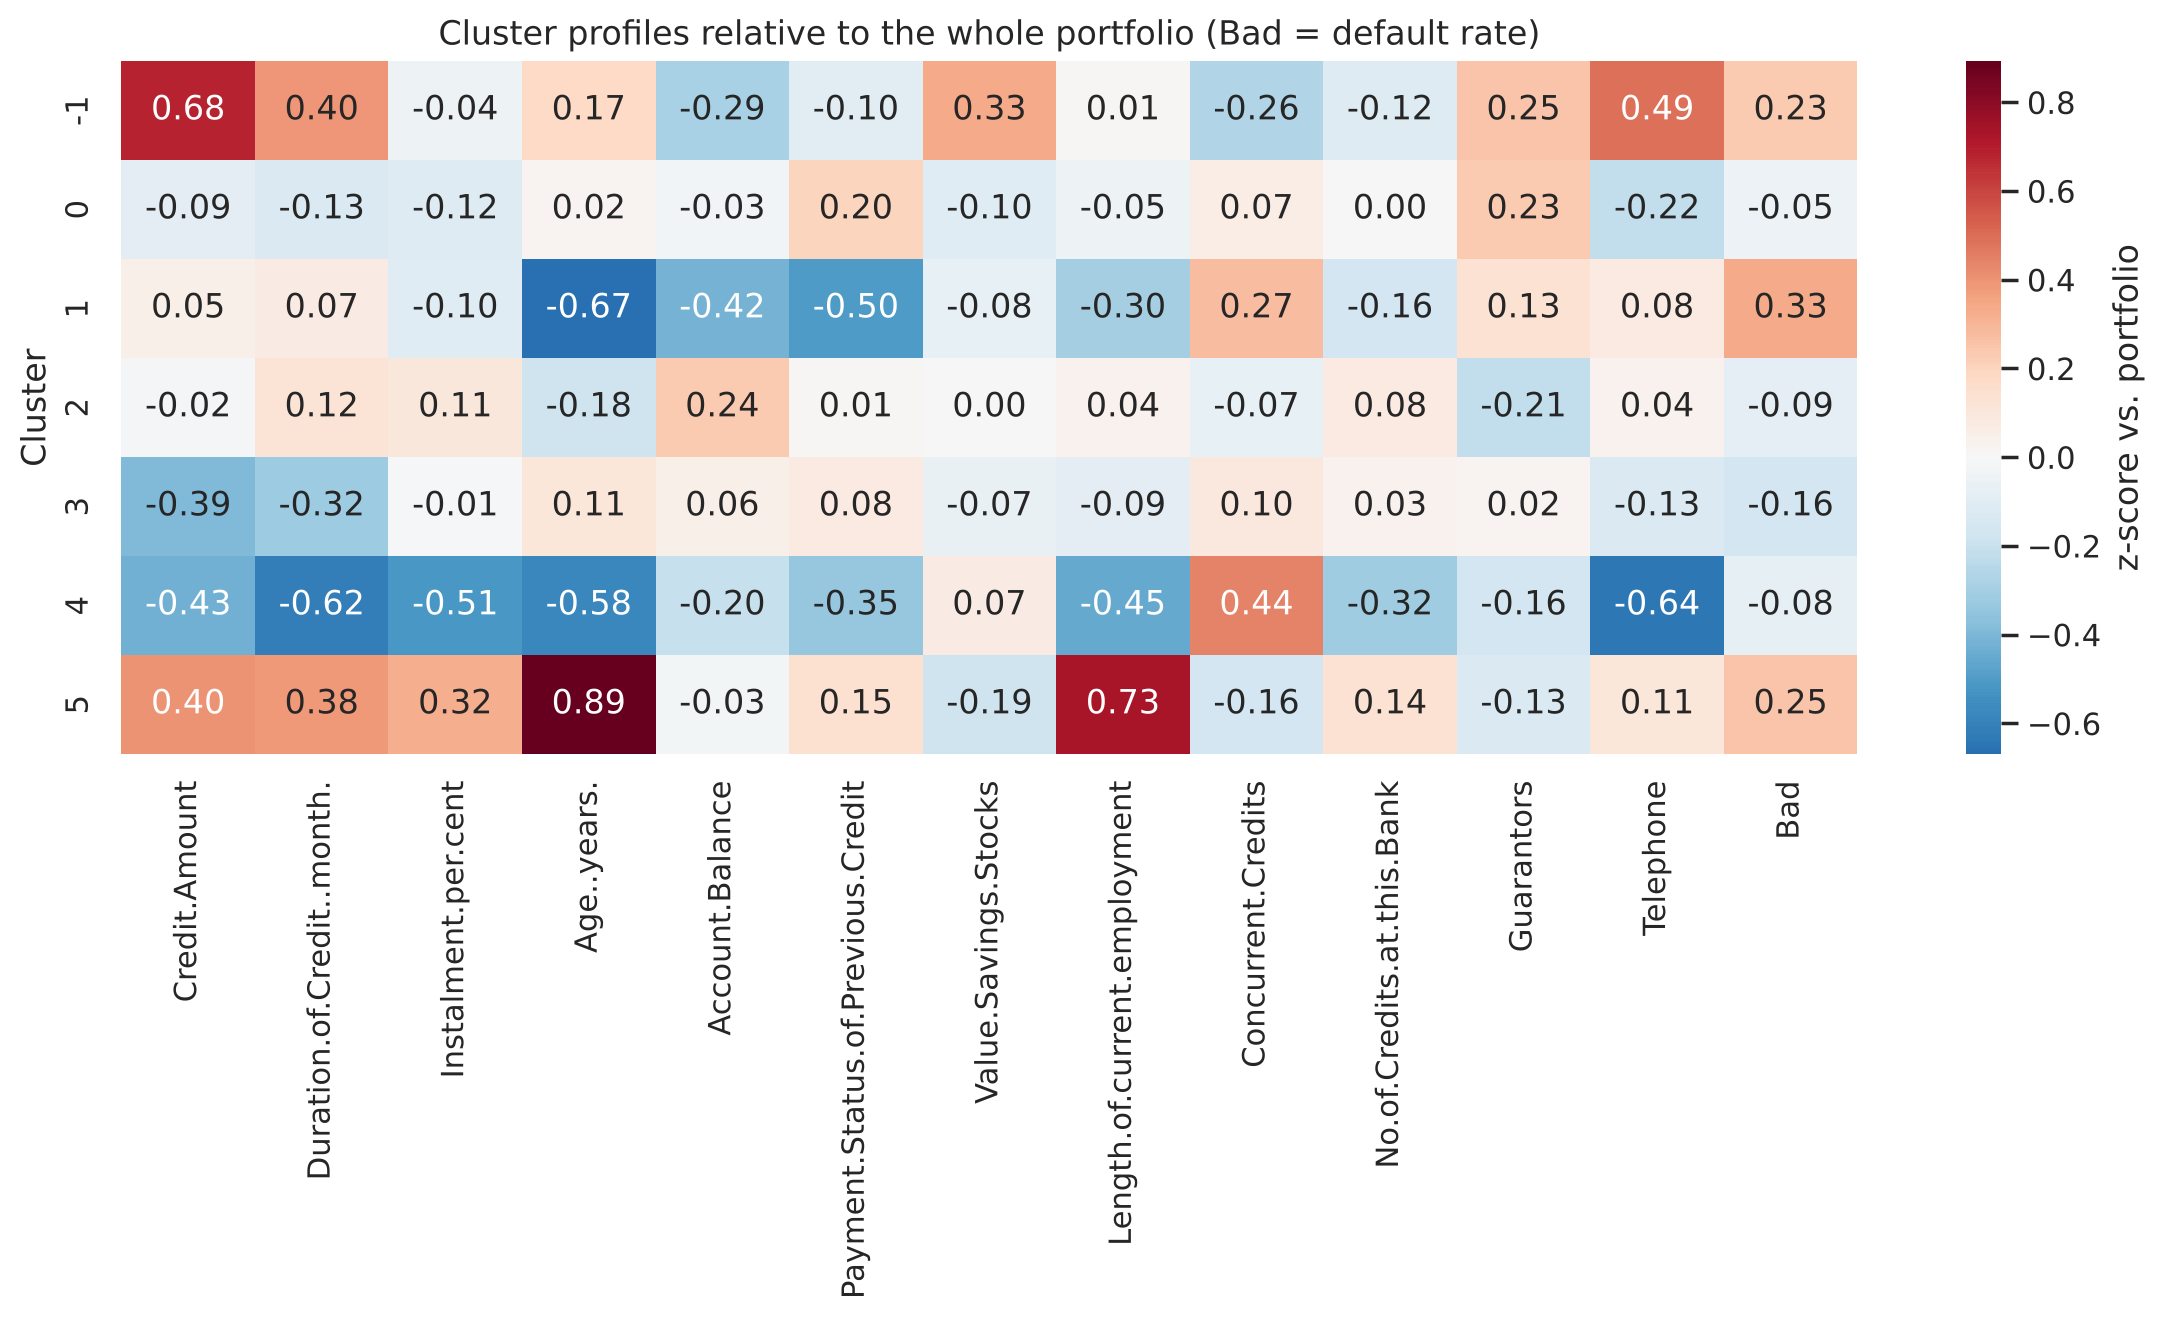

In [22]:
heat_cols = ["Credit.Amount", "Duration.of.Credit..month.", "Instalment.per.cent", "Age..years.", "Account.Balance",
             "Payment.Status.of.Previous.Credit", "Value.Savings.Stocks", "Length.of.current.employment",
             "Concurrent.Credits", "No.of.Credits.at.this.Bank", "Guarantors", "Telephone", "Bad"]
z = (df_res.groupby("Cluster")[heat_cols].mean() - df_res[heat_cols].mean()) / df_res[heat_cols].std()
plt.figure(figsize=(14, 4.5))
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score vs. portfolio"})
plt.title("Cluster profiles relative to the whole portfolio (Bad = default rate)"); plt.ylabel("Cluster"); plt.show()

### 4.3 Loan size, duration and age by cluster

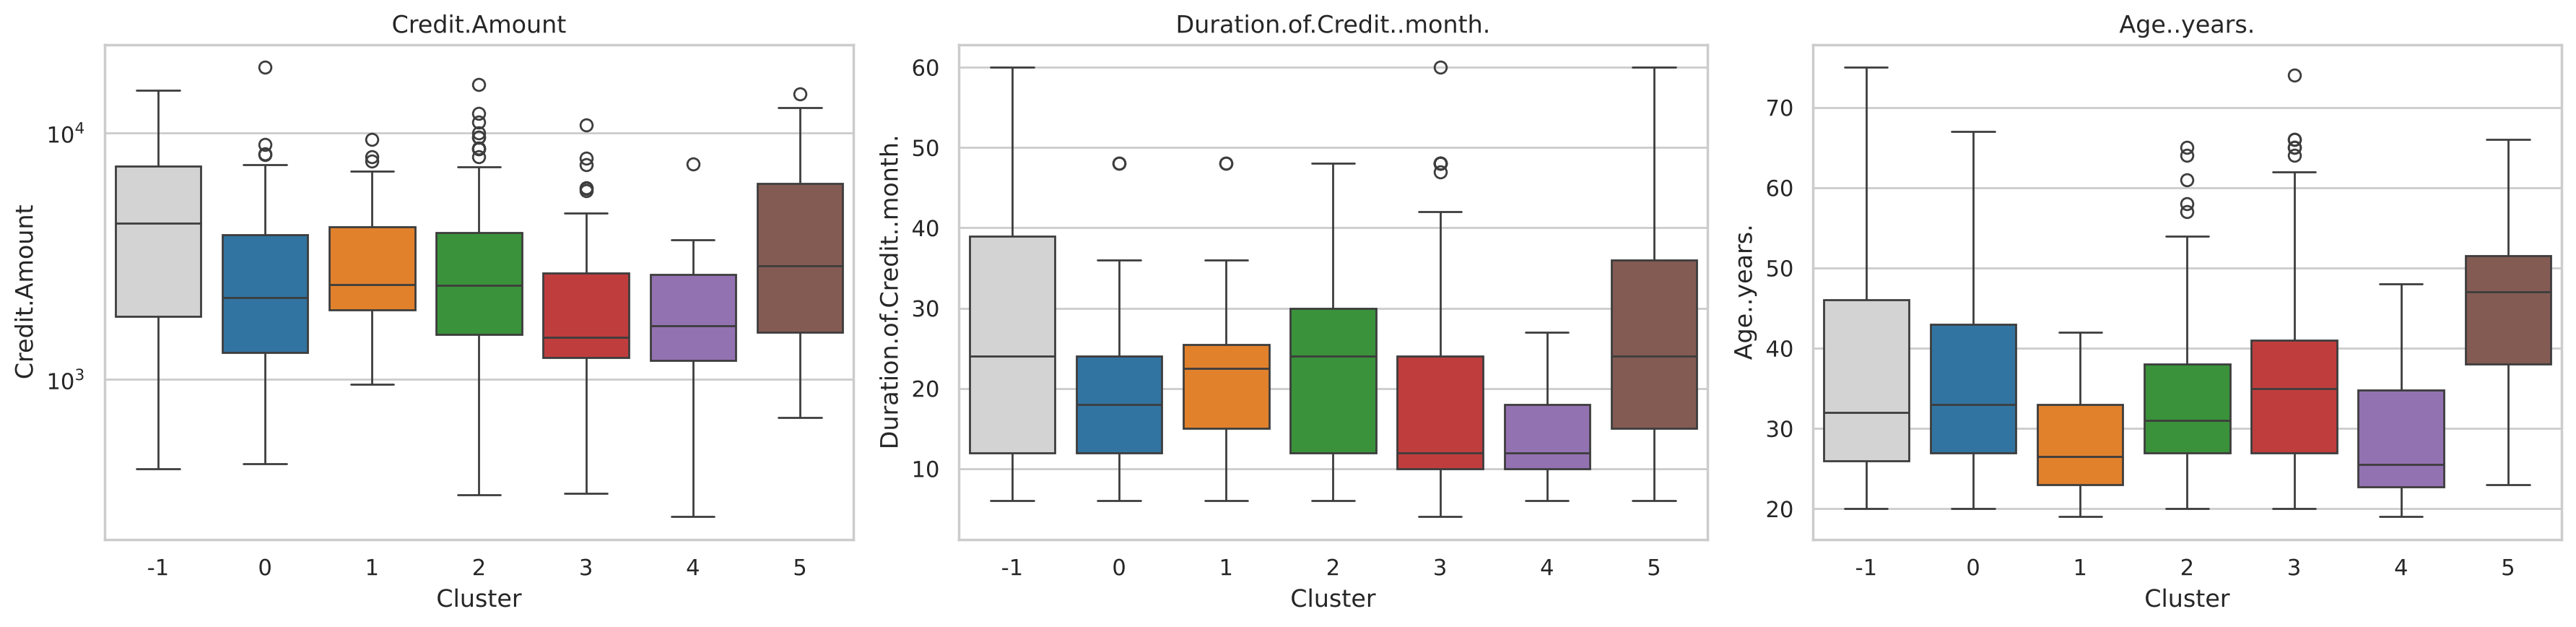

In [23]:
order = sorted(df_res.Cluster.unique())
pal = dict(zip(order, ["lightgrey"] + sns.color_palette("tab10", len(order) - 1)))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, ["Credit.Amount", "Duration.of.Credit..month.", "Age..years."]):
    sns.boxplot(x=df_res["Cluster"].astype(str), y=df_res[col], order=[str(c) for c in order],
                hue=df_res["Cluster"].astype(str), palette={str(k): v for k, v in pal.items()}, legend=False, ax=ax)
    ax.set_title(col)
axes[0].set_yscale("log")
plt.tight_layout(); plt.show()

### 4.4 Credit history, liquidity and employment by cluster

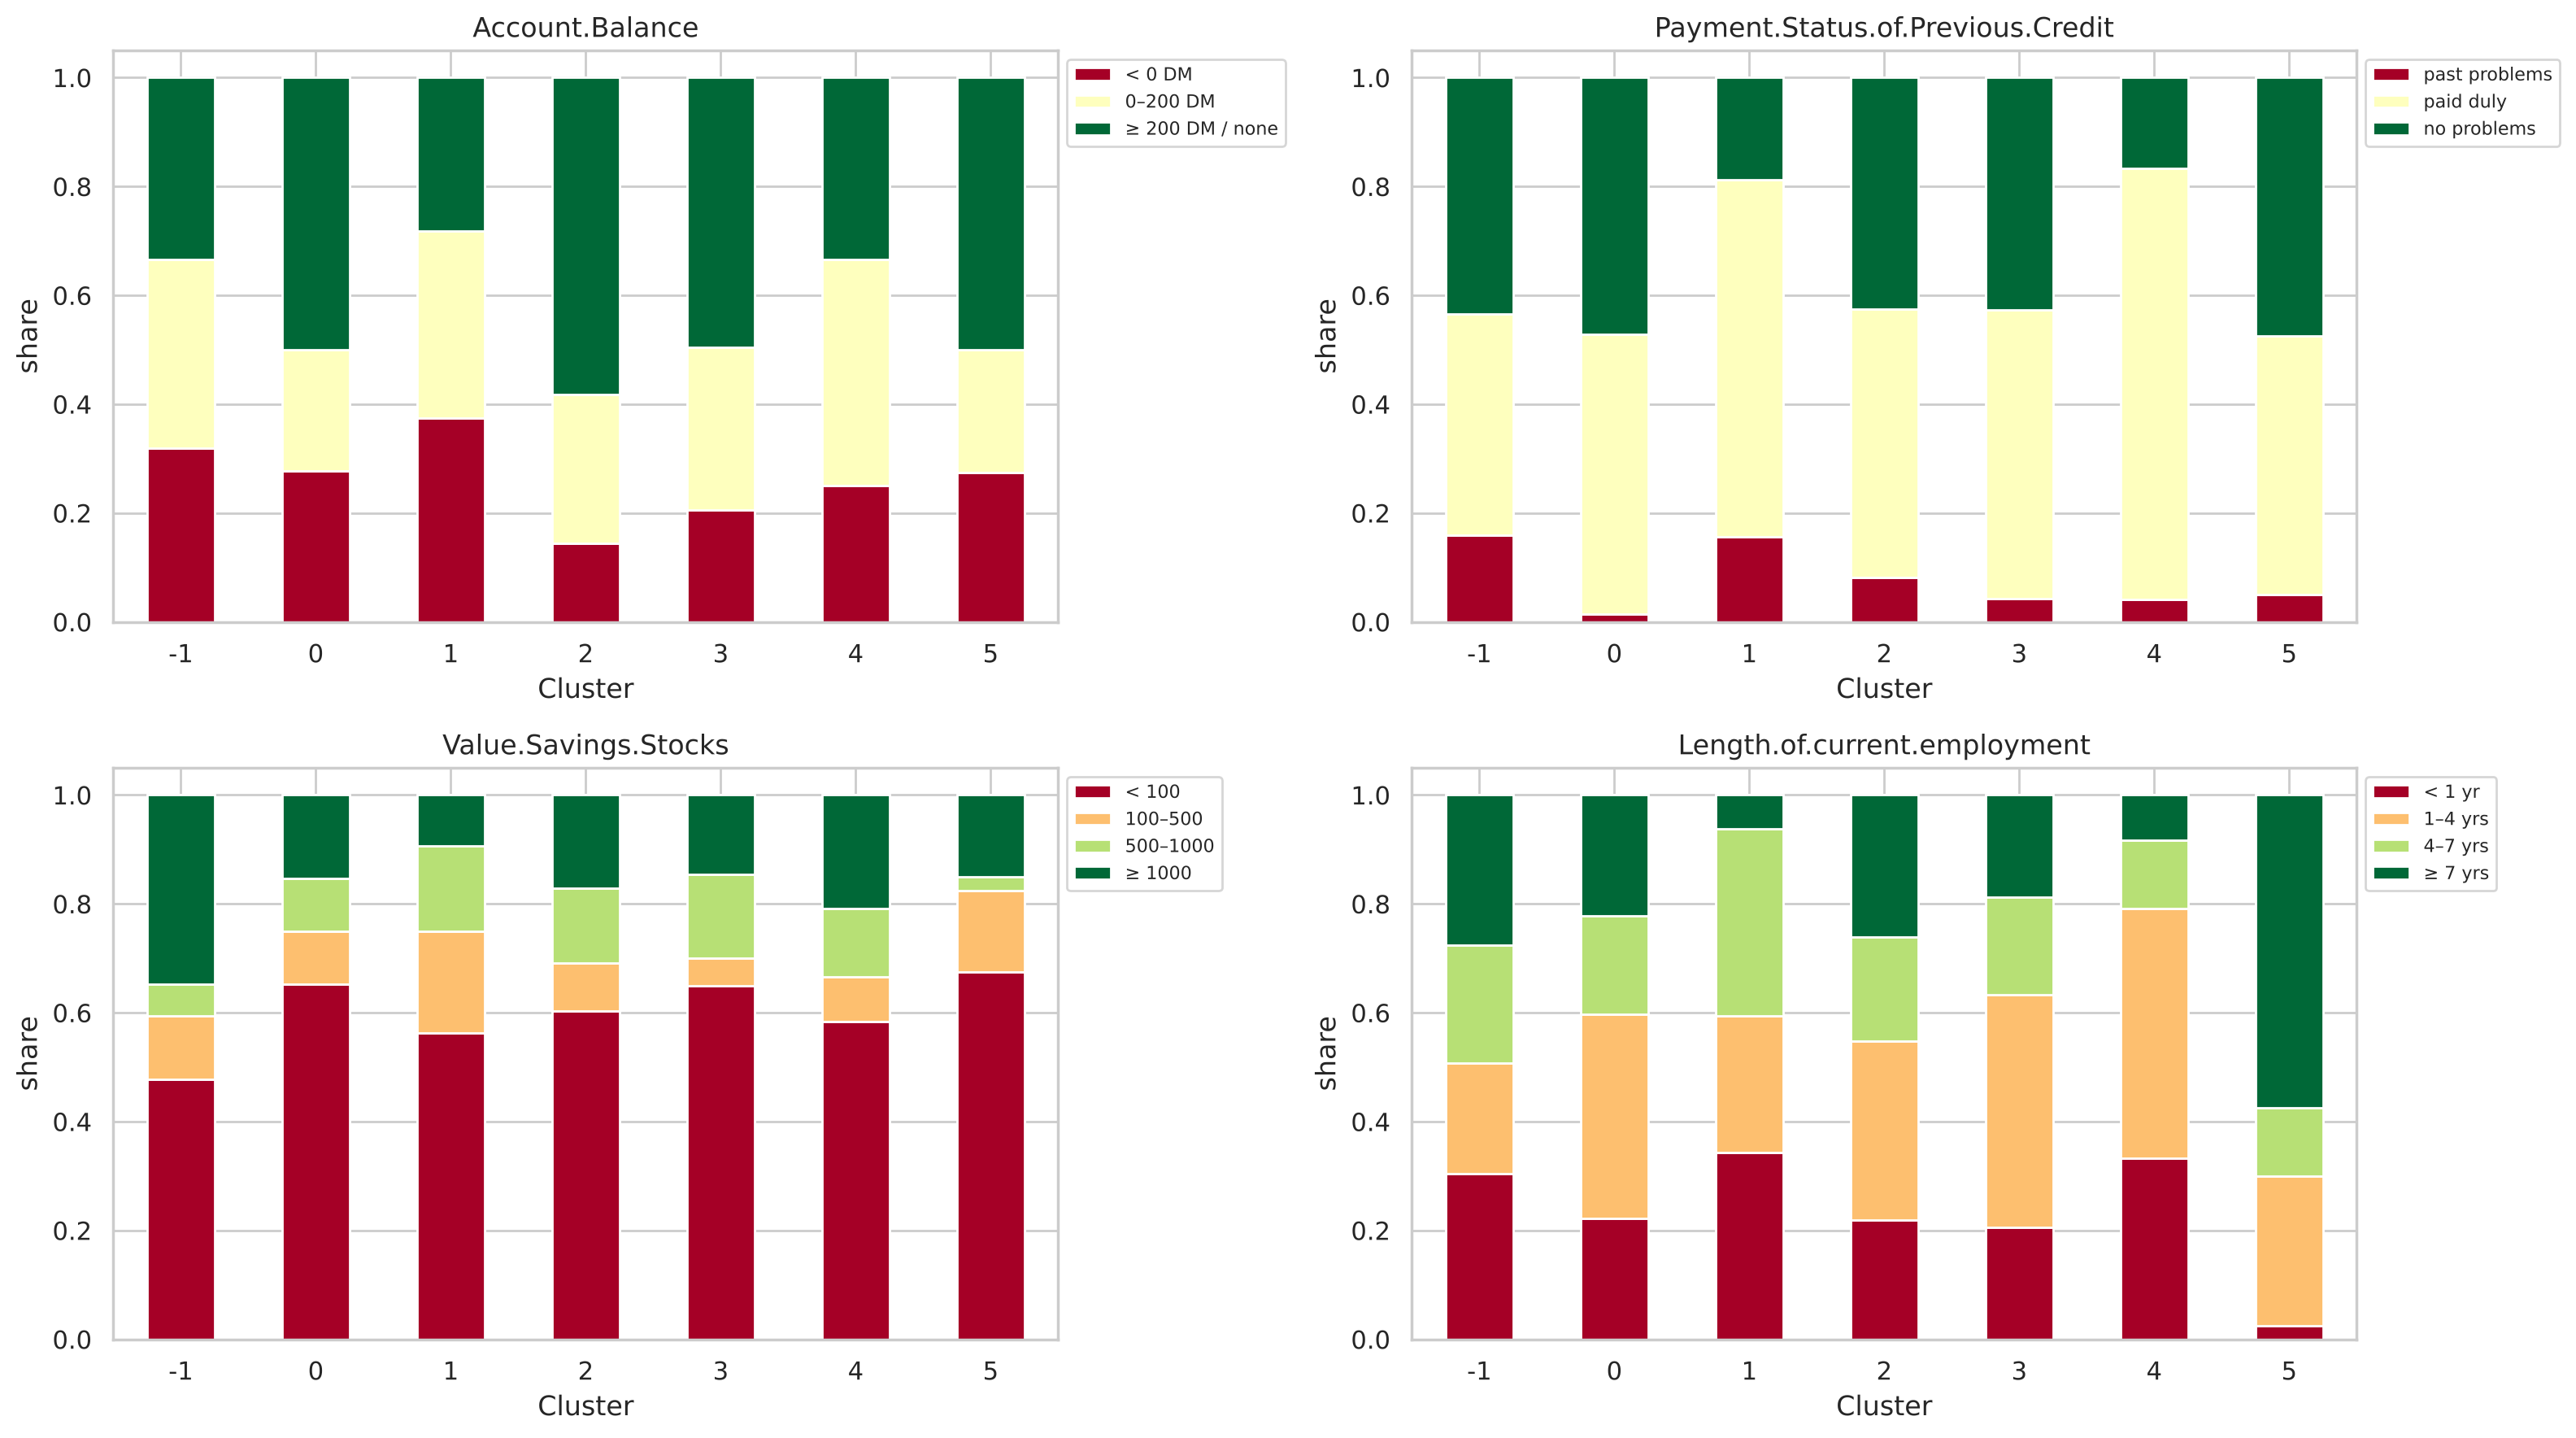

In [24]:
labels_map = {
    "Account.Balance": {1: "< 0 DM", 2: "0–200 DM", 3: "≥ 200 DM / none"},
    "Payment.Status.of.Previous.Credit": {1: "past problems", 2: "paid duly", 3: "no problems"},
    "Value.Savings.Stocks": {1: "< 100", 2: "100–500", 3: "500–1000", 4: "≥ 1000"},
    "Length.of.current.employment": {1: "< 1 yr", 2: "1–4 yrs", 3: "4–7 yrs", 4: "≥ 7 yrs"},
}
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, (col, mp) in zip(axes.ravel(), labels_map.items()):
    ct = pd.crosstab(df_res["Cluster"], df_res[col].map(mp), normalize="index")[list(mp.values())]
    ct.plot.bar(stacked=True, ax=ax, colormap="RdYlGn", edgecolor="white", rot=0)
    ax.set_title(col); ax.set_ylabel("share"); ax.legend(fontsize=8, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

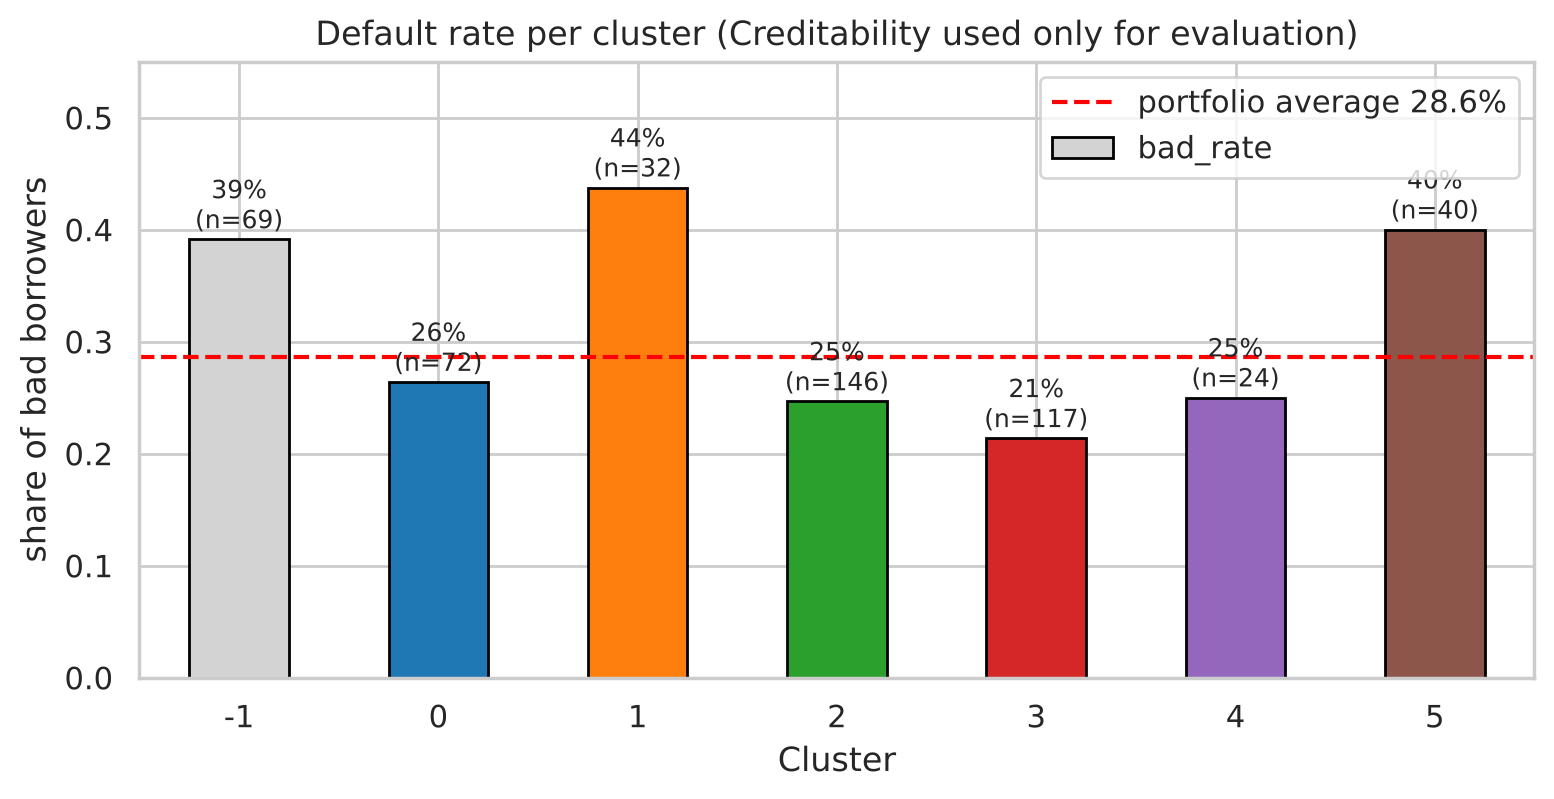

In [25]:
risk = df_res.groupby("Cluster").agg(customers=("Bad", "size"), bad_rate=("Bad", "mean"))
ax = risk["bad_rate"].plot.bar(color=[pal[c] for c in risk.index], edgecolor="black", figsize=(9, 4), rot=0)
ax.axhline(df_res["Bad"].mean(), ls="--", c="red", label=f"portfolio average {df_res['Bad'].mean():.1%}")
for i, (n, br) in enumerate(zip(risk.customers, risk.bad_rate)):
    ax.text(i, br + 0.01, f"{br:.0%}\n(n={n})", ha="center", fontsize=9)
ax.set_ylim(0, 0.55); ax.set_ylabel("share of bad borrowers"); ax.set_title("Default rate per cluster (Creditability used only for evaluation)")
ax.legend(); plt.show()

**What separates the clusters.** The cross-table above shows that every cluster is a **pure combination of housing and main asset** (100 % one housing type, 100 % one asset type). These two variables form the "skeleton" of density: customers with the same housing/asset situation are close to each other, and inside each such group the continuous variables (loan amount, duration, age) decide who is a dense core member and who is an outlier (noise). This is financially meaningful: *housing + collateral* describe the **wealth and stability** of a borrower, and the clusters differ clearly in age, loan size, credit history and risk (21 % – 44 % default rate, see the bar chart).

Two big "risk families" appear:

* **Homeowners (clusters 0, 2, 3 — 335 customers):** default rate 21–26 %, below the portfolio average of 28.6 %.
* **Renters and people without property (clusters 1, 5):** 40–44 % default rate. Cluster 4 is the exception among renters (25 %) because it takes very small, short loans.

## 5. Common patterns and reasons for cluster membership

The table below lists, for every cluster, the features in which it deviates most from the portfolio (largest |z|). This is the "why" behind the membership.

In [26]:
def top_features(cl, n=5):
    s = z.loc[cl].drop("Bad")
    s = s.reindex(s.abs().sort_values(ascending=False).index)[:n]
    return ", ".join(f"{k} {'↑' if v > 0 else '↓'} ({v:+.2f})" for k, v in s.items())

pd.DataFrame({"size": df_res.groupby("Cluster").size(),
              "bad rate": df_res.groupby("Cluster")["Bad"].mean().map("{:.0%}".format),
              "most distinctive features (z vs portfolio)": [top_features(c) for c in sorted(df_res.Cluster.unique())]})

,size,bad rate,most distinctive features (z vs portfolio)
Cluster,,,
-1,69,39%,"Credit.Amount ↑ (+0.68), Telephone ↑ (+0.49), ..."
0,72,26%,"Guarantors ↑ (+0.23), Telephone ↓ (-0.22), Pay..."
1,32,44%,"Age..years. ↓ (-0.67), Payment.Status.of.Previ..."
2,146,25%,"Account.Balance ↑ (+0.24), Guarantors ↓ (-0.21..."
3,117,21%,"Credit.Amount ↓ (-0.39), Duration.of.Credit..m..."
4,24,25%,"Telephone ↓ (-0.64), Duration.of.Credit..month..."
5,40,40%,"Age..years. ↑ (+0.89), Length.of.current.emplo..."


### Segment descriptions

**Cluster 3 — Established real-estate owners (117 customers, default rate 21 % — lowest risk)**
Own their home *and* real estate is their main asset. They borrow the **smallest amounts among homeowners** (median 1 473 DM) for the **shortest terms** (17.6 months, only 10 % ≥ 36 months), age ≈ 37, only 4 % had past payment problems, 50 % hold a healthy current account.
*Why together:* property owners who finance small everyday purchases — strong collateral and a small exposure relative to their wealth → the safest segment.

**Cluster 2 — Car-owning homeowners, the "core" of the portfolio (146 customers, 25 %)**
Own their home, main asset = car. **Best current-account position in the portfolio** (58 % with ≥ 200 DM, only 14 % negative), medium loans (median 2 405 DM, 23 months), age ≈ 33, almost never need a guarantor (3 %).
*Why together:* typical middle-class borrowers with stable housing and good liquidity — average-to-low risk, the bank's mainstream customers.

**Cluster 0 — Homeowners with financial assets (72 customers, 26 %)**
Own their home, main asset = savings agreement / life insurance. **Cleanest credit history** (only 1 % past problems), the **highest use of guarantors** (15 %), medium loans (median 2 146 DM, 20 months), age ≈ 36.
*Why together:* financially disciplined savers; risk is slightly below average.

**Cluster 4 — Young renters with small short loans (24 customers, 25 %)**
Rent, but own real estate (e.g. inherited or bought for investment). **Young** (28.8 years, 42 % under 25), **short employment** (33 % < 1 year), almost no telephone (8 %), **no concurrent credits at all**. But they take the **smallest and shortest loans** (median 1 641 DM, 14 months, none ≥ 36 months) and have the **lowest instalment burden**.
*Why together:* young people at the start of their career who borrow cautiously; small exposure keeps the risk at an average level despite the weak employment profile.

**Cluster 1 — Young renters with weak liquidity (32 customers, 44 % — highest risk)**
Rent, main asset = car. **Youngest group** (27.8 years, 44 % under 25), **highest share of negative current accounts** (38 % vs 23 % overall), **weak credit history** (16 % past problems, only 19 % "no problems" vs 41 % overall), 34 % employed for less than a year, 56 % have savings < 100 DM. Yet the loans are not small (median 2 417 DM, 22 months).
*Why together:* young borrowers with no housing stability, little liquidity and a short or problematic history who finance a car or consumption — classic high-risk retail profile.

**Cluster 5 — Older non-owners with large long loans (40 customers, 40 %)**
Live for free (with family / employer housing) and have **no property**. **Oldest group** (45.7 years) with the **longest employment** (57 % ≥ 7 years), but they take **large and long loans** (median 2 877 DM, 35 % above 5 000 DM, 32 % ≥ 36 months) with the **heaviest instalment burden** (60 % at the maximum level 4).
*Why together:* long employment would suggest stability, but without property or own housing there is **no collateral**, and the loans are big relative to income → high risk. A good example that "stable job" alone is not enough.

**Noise — Atypical / large-loan applicants (69 customers, 39 %)** — see section 3.1.

### Common patterns across segments

1. **Wealth and housing are the main density drivers** — and also strong risk drivers: owning a home (+ real estate) ↔ low risk, no property / free housing ↔ high risk.
2. **Age + liquidity**: the two youngest groups differ mainly by account balance, credit history and loan size — that is exactly why one has 25 % and the other 44 % default rate.
3. **Exposure matters**: segments with large, long loans (cluster 5, noise) are risky even with long employment or high savings.
4. **Credit history** (payment problems) concentrates in the young renters (cluster 1) and the noise points.

## 6. Visualization and interpretation

*(DBSCAN has already been fitted in section 3; here we only draw its result. Extra non-linear views — t-SNE and UMAP — are in sections 8 and 9, after the conclusions.)*

### 6.1 PCA projection

PCA projects the 14-dimensional standardized space onto the two directions of largest variance. It is a **linear** projection, so it preserves global structure but can overlap clusters that are separated in other dimensions.

Explained variance: [0.2   0.137] total: 0.336


,PC1,PC2
Type.of.apartment_1,0.04,0.53
Most.valuable.available.asset_4,0.52,-0.13
Type.of.apartment_3,0.52,-0.14
Age..years.,0.19,-0.42
Type.of.apartment_2,-0.39,-0.35
Payment.Status.of.Previous.Credit,0.02,-0.33
Credit.Amount,0.30,0.15
Duration.of.Credit..month.,0.28,0.17


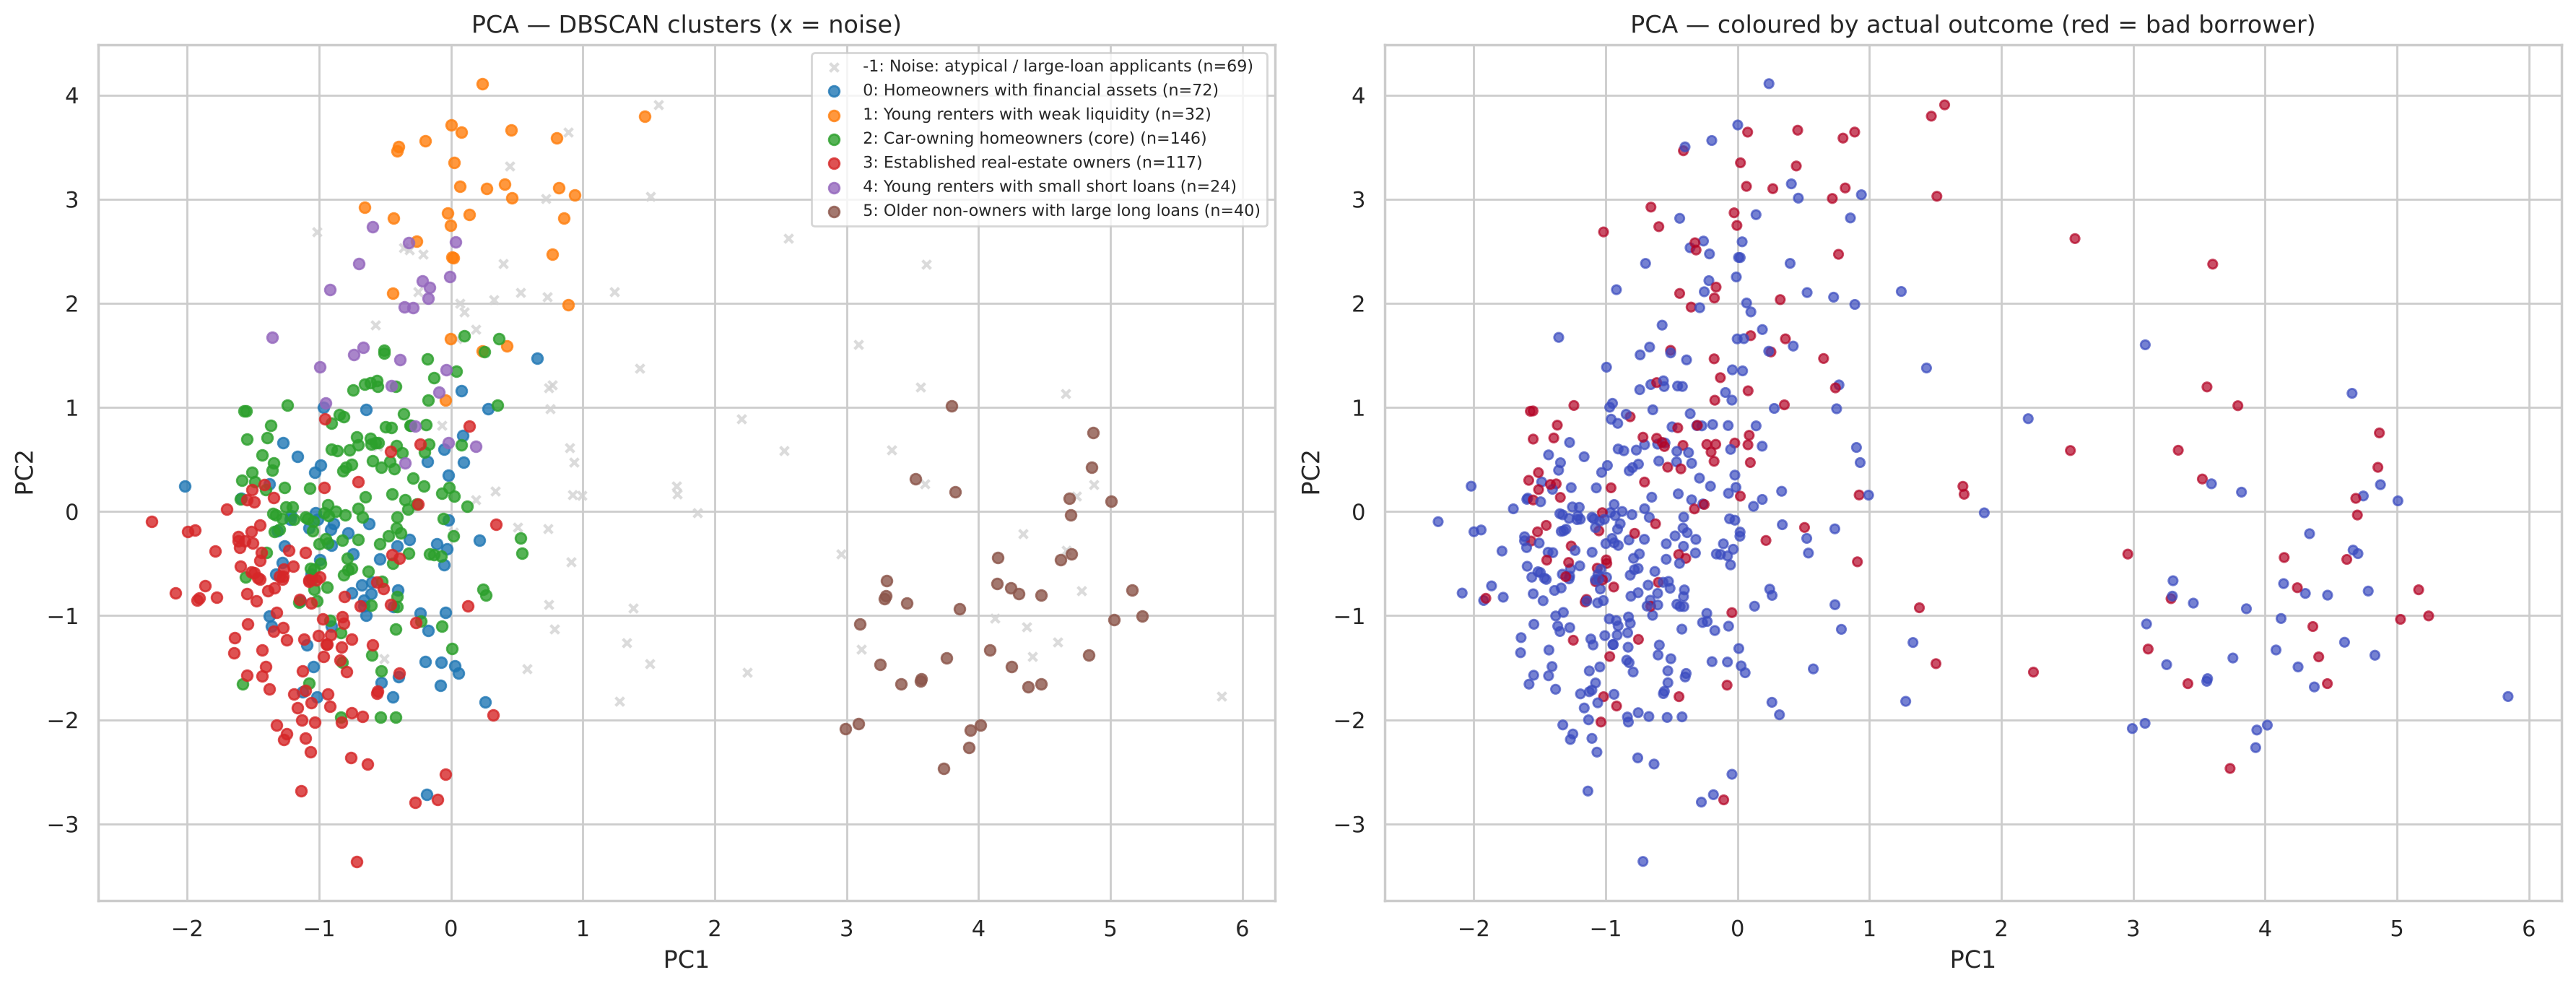

In [27]:
SEGMENT_NAMES = {-1: "Noise: atypical / large-loan applicants",
                  0: "Homeowners with financial assets",
                  1: "Young renters with weak liquidity",
                  2: "Car-owning homeowners (core)",
                  3: "Established real-estate owners",
                  4: "Young renters with small short loans",
                  5: "Older non-owners with large long loans"}
df_res["Segment"] = df_res["Cluster"].map(SEGMENT_NAMES)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
P = pca.fit_transform(X)
print("Explained variance:", pca.explained_variance_ratio_.round(3), "total:", pca.explained_variance_ratio_.sum().round(3))

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
display(loadings.reindex(loadings.abs().max(axis=1).sort_values(ascending=False).index).head(8).round(2))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for cl in order:
    m = labels == cl
    axes[0].scatter(P[m, 0], P[m, 1], s=18 if cl == -1 else 28, c=[pal[cl]], marker="x" if cl == -1 else "o",
                    alpha=0.8, label=f"{cl}: {SEGMENT_NAMES[cl]} (n={m.sum()})")
axes[0].set_title("PCA — DBSCAN clusters (x = noise)"); axes[0].legend(fontsize=8, loc="best")
sc = axes[1].scatter(P[:, 0], P[:, 1], c=df_res["Bad"], cmap="coolwarm", s=20, alpha=0.7)
axes[1].set_title("PCA — coloured by actual outcome (red = bad borrower)")
for ax in axes: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

### 6.2 Side-by-side comparison of the segments

In [28]:
summary = df_res.groupby("Cluster").agg(
    Segment=("Segment", "first"),
    Customers=("Bad", "size"),
    Median_amount=("Credit.Amount", "median"),
    Mean_duration=("Duration.of.Credit..month.", "mean"),
    Mean_age=("Age..years.", "mean"),
    Neg_balance_share=("Account.Balance", lambda s: (s == 1).mean()),
    Past_problems_share=("Payment.Status.of.Previous.Credit", lambda s: (s == 1).mean()),
    Low_savings_share=("Value.Savings.Stocks", lambda s: (s == 1).mean()),
    Long_employment_share=("Length.of.current.employment", lambda s: (s >= 3).mean()),
    Bad_rate=("Bad", "mean"))
summary.style.format({"Median_amount": "{:,.0f}", "Mean_duration": "{:.1f}", "Mean_age": "{:.1f}",
                      "Neg_balance_share": "{:.0%}", "Past_problems_share": "{:.0%}", "Low_savings_share": "{:.0%}",
                      "Long_employment_share": "{:.0%}", "Bad_rate": "{:.0%}"}) \
             .background_gradient(subset=["Bad_rate"], cmap="Reds")

,Segment,Customers,Median_amount,Mean_duration,Mean_age,Neg_balance_share,Past_problems_share,Low_savings_share,Long_employment_share,Bad_rate
Cluster,,,,,,,,,,
-1,Noise: atypical / large-loan applicants,69,"4,297",26.4,37.4,32%,16%,48%,49%,39%
0,Homeowners with financial assets,72,"2,146",19.9,35.7,28%,1%,65%,40%,26%
1,Young renters with weak liquidity,32,"2,417",22.4,27.8,38%,16%,56%,41%,44%
2,Car-owning homeowners (core),146,"2,405",23.0,33.4,14%,8%,60%,45%,25%
3,Established real-estate owners,117,"1,473",17.6,36.7,21%,4%,65%,37%,21%
4,Young renters with small short loans,24,"1,640",14.0,28.8,25%,4%,58%,21%,25%
5,Older non-owners with large long loans,40,"2,877",26.3,45.6,28%,5%,68%,70%,40%


**Interpretation of the PCA projection**

* The two components explain only **33.6 %** of the variance. PC1 is driven by *no property + free housing* (and loan size), PC2 by *renting vs owning* and age.
* Cluster 5 (older non-owners) is clearly separated on the right; the young renters (clusters 1 and 4) are at the top; the three homeowner groups (0, 2, 3) overlap in the lower-left, because they differ mainly in the asset type, which is not represented in PC1–PC2. Noise points lie between the groups and at the edges — they do not belong to any dense region.
* **Comparison with the real outcome (right plot):** red points (bad borrowers) are more frequent in the region of clusters 1 and 5 and among the noise, while the lower-left region with cluster 3 is mostly blue. The clustering was done **without** the target, so this confirms that the density segments carry genuine credit-risk information. Every region still contains both colours: clusters describe *profiles*, they do not replace an individual credit score.
* Because PCA is linear and shows only a third of the information, non-linear views of the **same** DBSCAN labels (t-SNE, UMAP) are added in sections 8–9.

## 7. Conclusions

**Main findings**

1. On all 28 encoded features DBSCAN fails (one giant cluster + noise) because of the curse of dimensionality and many irrelevant variables. Restricting the space to the **financial profile** (loan amount and duration, credit history, account balance, savings, employment, assets, housing, age) produces a clear and **stable** structure.
2. With **`eps = 2.85`, `min_samples = 15`** (middle of a stable plateau, just below the k-distance elbow) DBSCAN finds **6 segments + 13.8 % noise** (silhouette 0.29). The result is robust for eps 2.70–3.00 and min_samples 12–18.
3. The segments are organised around **wealth and housing**, and they differ systematically in age, loan exposure, liquidity and history:

| Segment | Size | Default rate | Key profile |
|---|---|---|---|
| Established real-estate owners (3) | 117 | **21 %** | own home + real estate, small short loans |
| Car-owning homeowners (2) | 146 | 25 % | best account balances, medium loans |
| Young renters with small loans (4) | 24 | 25 % | young, short jobs, but tiny short loans |
| Homeowners with financial assets (0) | 72 | 26 % | savers, cleanest credit history |
| Older non-owners, large loans (5) | 40 | **40 %** | no property, big long loans, heavy instalments |
| Young renters, weak liquidity (1) | 32 | **44 %** | negative balances, past problems, short employment |
| Noise — atypical applicants | 69 | 39 % | very large loans, contradictory profiles |

4. The target was **not** used for clustering, yet the default rate ranges from 21 % to 44 % between segments — the unsupervised segmentation discovers real risk differences.

**Practical significance for credit-risk management**

* **Risk-based policy per segment:** fast-track / better rates for clusters 3, 2 and 0; stricter limits, shorter maturities or required guarantors for clusters 1 and 5.
* **Product design:** cluster 4 shows that young applicants can be served safely with *small, short* loans; cluster 5 shows that long employment does not compensate for missing collateral on large long loans → cap amount/duration or require collateral.
* **Noise = manual review queue:** DBSCAN automatically flags the ~14 % of applications that are unlike any typical group (very large loans, contradictory data). These are where scorecards are least reliable and where fraud or data errors would appear.
* **Feature for scoring models:** the cluster label (or "is noise") can be added as a feature to a supervised model (logistic regression, gradient boosting), and separate scorecards can be built per segment.
* **Monitoring:** new applications can be assigned to the nearest core points; a growing share of noise or a shift toward clusters 1/5 is an early warning for portfolio quality.

**Limitations**

* No direct income variable — financial capacity is captured only through proxies.
* Most variables are coded categories; the one-hot housing/asset dummies strongly shape the distance, so the clusters are partly defined by these combinations (which is, however, financially meaningful).
* 500 customers is a small sample; parameters should be re-validated on the full data set, and DBSCAN with a single global `eps` cannot capture clusters of very different density (HDBSCAN or OPTICS would be a natural next step).

In [29]:
# Save the segmentation for further use
df_res.drop(columns=["k_dist"]).to_csv("Training50_dbscan_segments.csv")
print("Saved: Training50_dbscan_segments.csv")

Saved: Training50_dbscan_segments.csv


## 8. Extra: DBSCAN result visualised with t-SNE

**Order of operations (important):**

1. **DBSCAN first** — the clusters were already found in section 3 on the 14-dimensional standardized matrix `X` (`labels`). t-SNE has not been used anywhere before this point.
2. **t-SNE second** — t-SNE is computed only now, on the same `X`, just to get a 2-D picture.
3. The points of the t-SNE picture are coloured with the **labels DBSCAN already returned**.

So t-SNE does **not** take part in the clustering and cannot change it; the cell below checks this explicitly.

DBSCAN labels unchanged after t-SNE: True


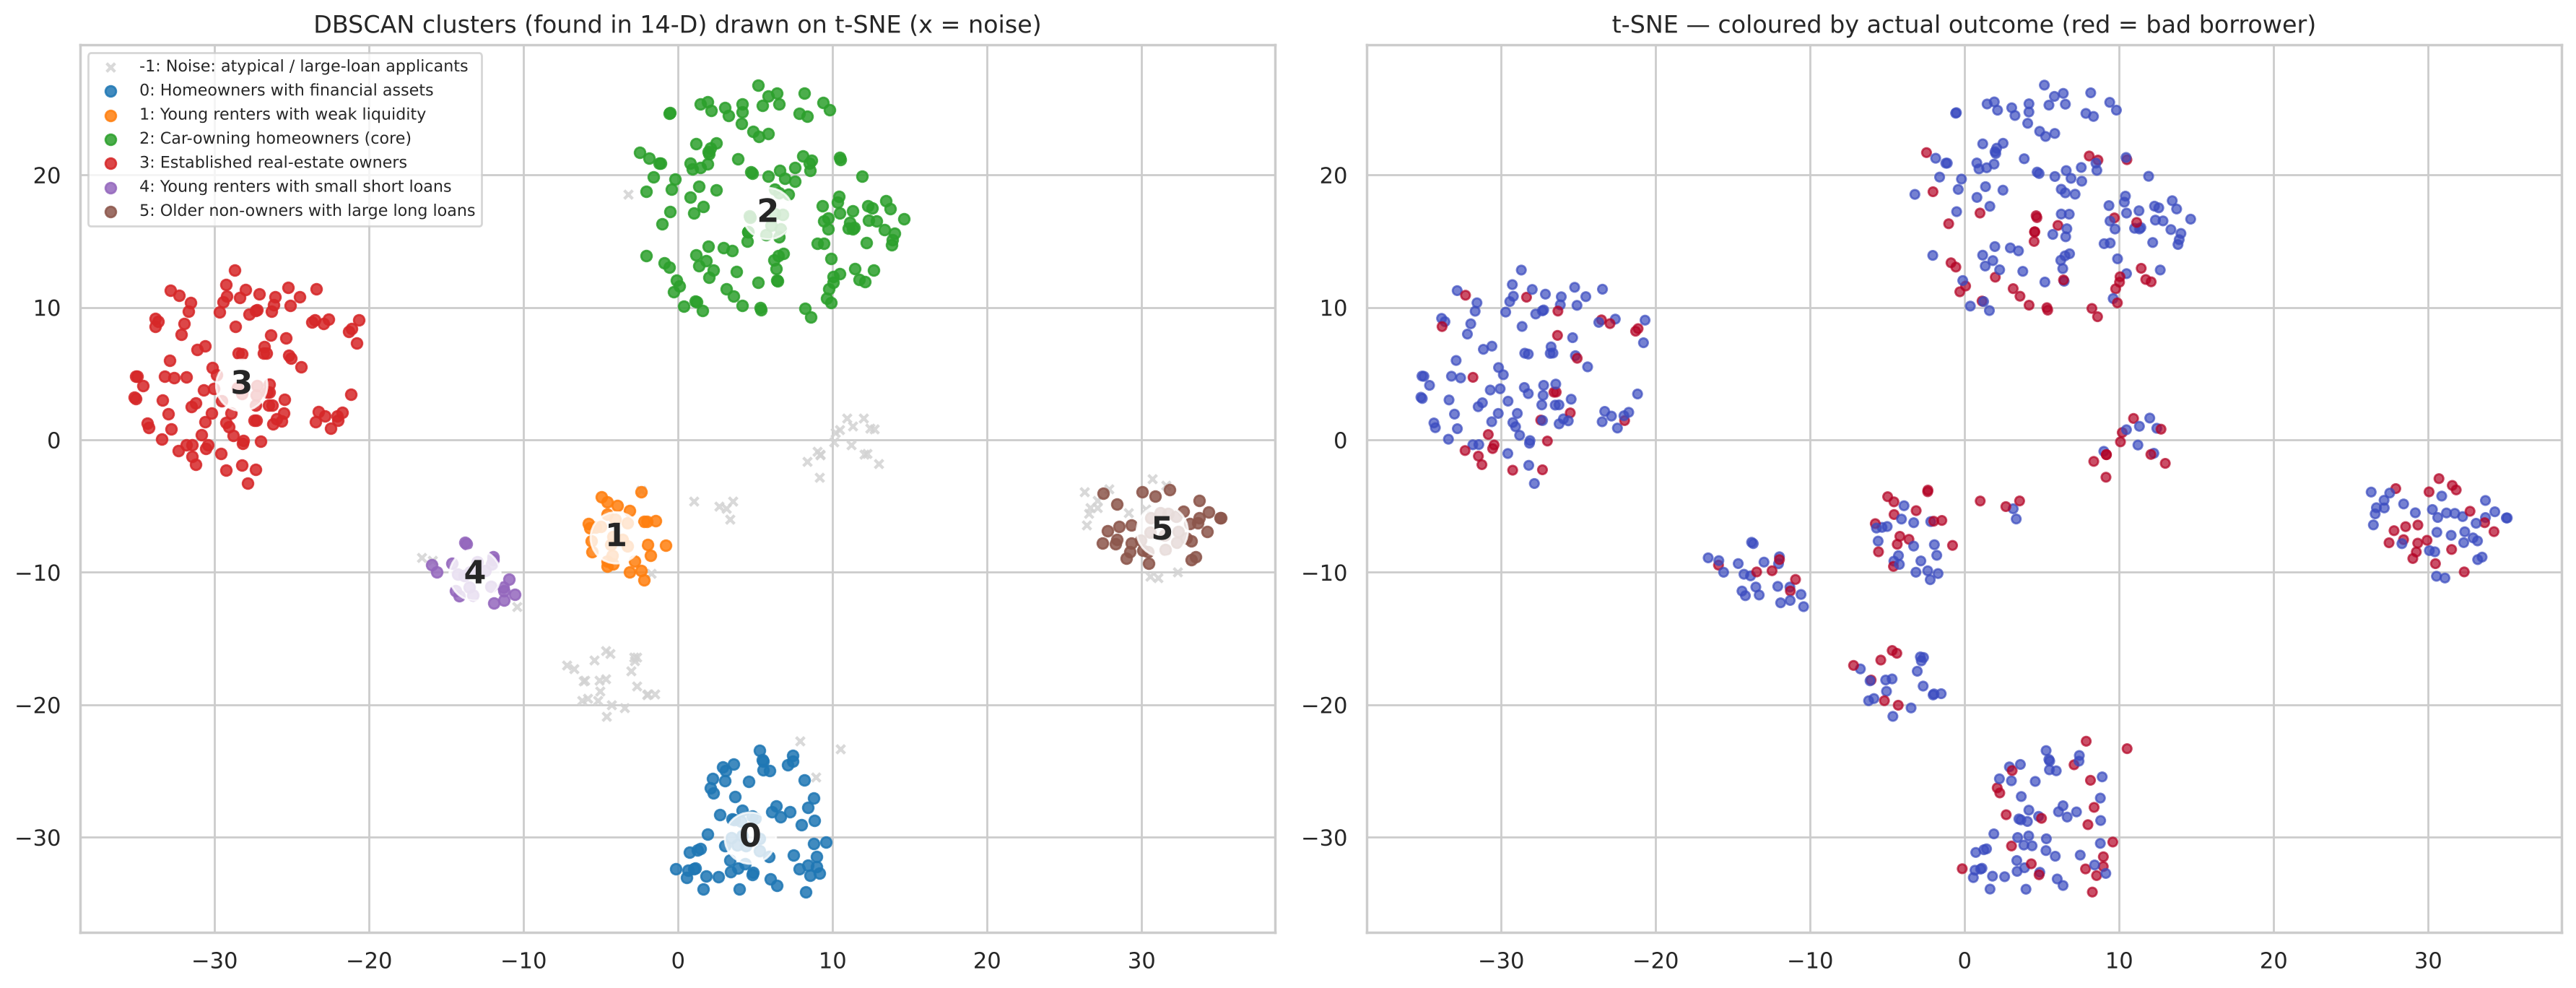

In [30]:
from sklearn.manifold import TSNE

labels_before_tsne = labels.copy()            # result of DBSCAN from section 3

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=RANDOM_STATE)
T = tsne.fit_transform(X)                       # 2-D picture only

assert (labels == labels_before_tsne).all()     # clusters are unchanged by t-SNE
print("DBSCAN labels unchanged after t-SNE:", (labels == labels_before_tsne).all())

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for cl in order:
    m = labels == cl
    axes[0].scatter(T[m, 0], T[m, 1], s=18 if cl == -1 else 28, c=[pal[cl]], marker="x" if cl == -1 else "o",
                    alpha=0.85, label=f"{cl}: {SEGMENT_NAMES[cl]}")
    if cl != -1:
        cx, cy = np.median(T[m, 0]), np.median(T[m, 1])
        axes[0].text(cx, cy, str(cl), fontsize=16, weight="bold", ha="center", va="center",
                     bbox=dict(boxstyle="circle", fc="white", alpha=0.8))
axes[0].set_title("DBSCAN clusters (found in 14-D) drawn on t-SNE (x = noise)"); axes[0].legend(fontsize=8, loc="best")
axes[1].scatter(T[:, 0], T[:, 1], c=df_res["Bad"], cmap="coolwarm", s=20, alpha=0.7)
axes[1].set_title("t-SNE — coloured by actual outcome (red = bad borrower)")
plt.tight_layout(); plt.show()

### 8.1 Different `eps` on the t-SNE picture

Same procedure as in 2.7: for each `eps` DBSCAN is fitted on `X` (14-D) and the result is drawn on the t-SNE coordinates `T`.

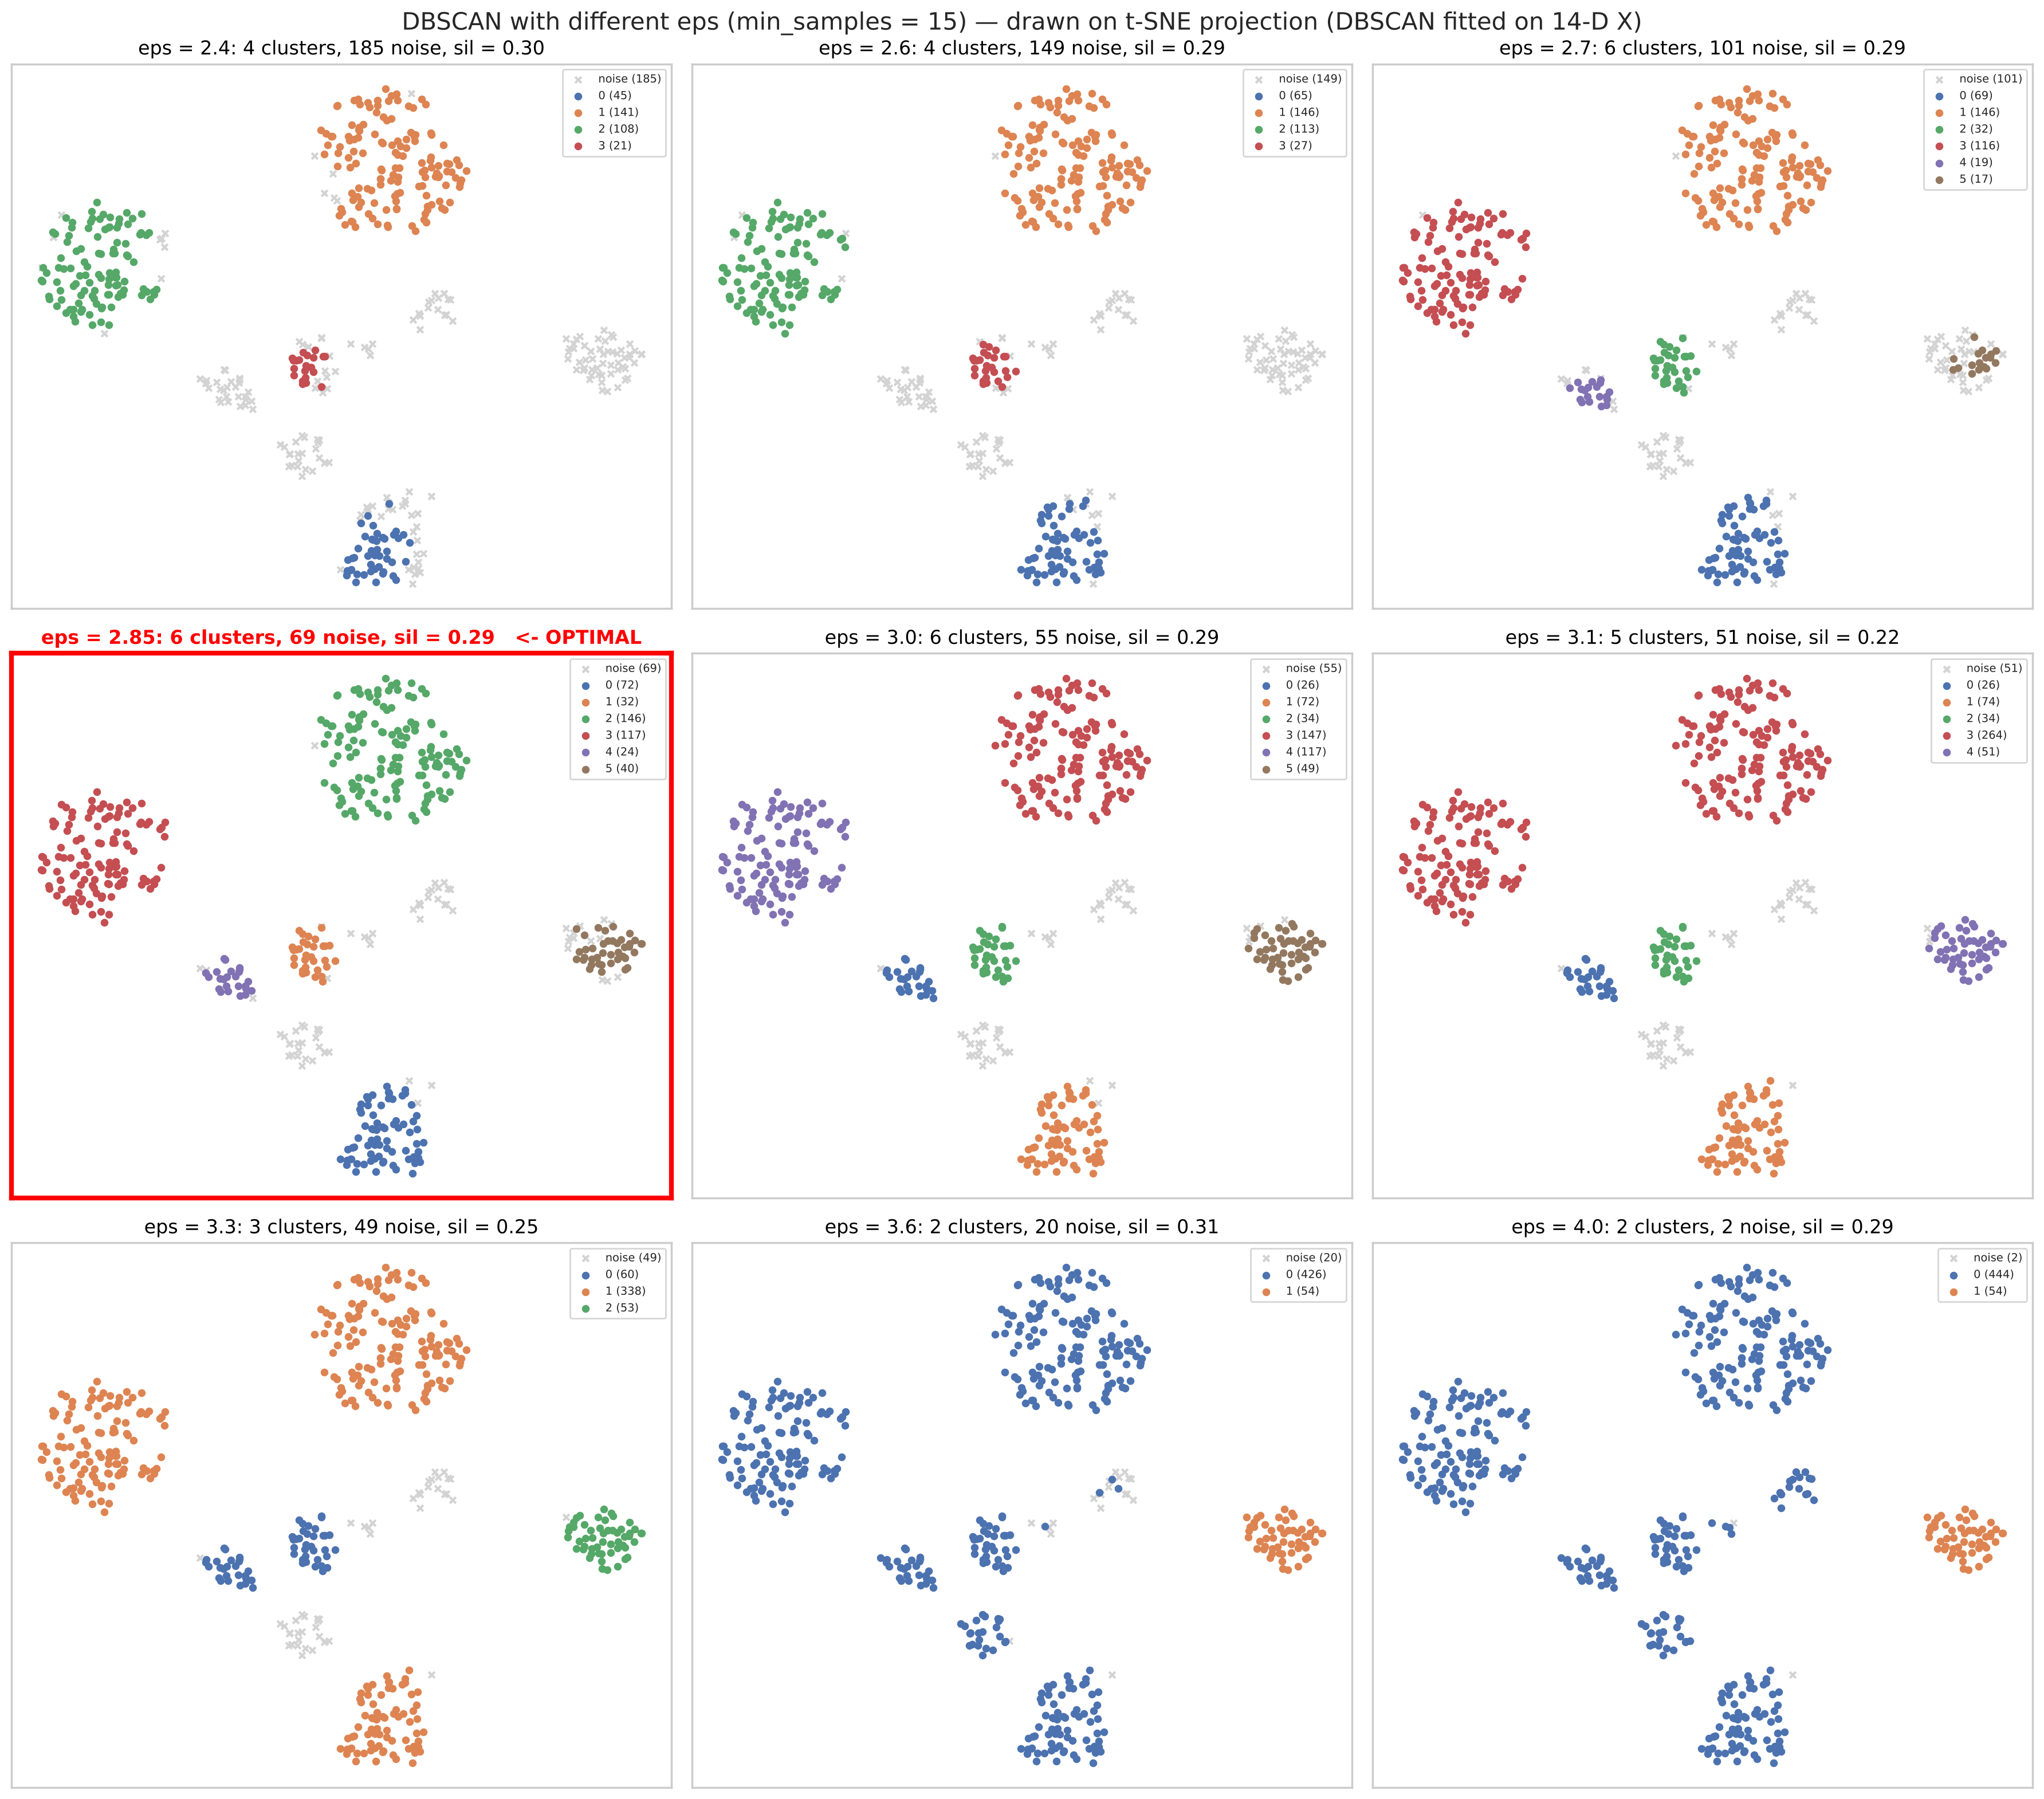

In [31]:
plot_eps_grid(T, "t-SNE projection (DBSCAN fitted on 14-D X)", EPS_SHOW, eps_opt=EPS_OPT)

**How to read the t-SNE grid.** Same 9 values of `eps` as in 2.7 and the same clusters — only the picture is different. t-SNE keeps local neighbourhoods, so the dense groups appear as separate **islands**.

* **eps = 2.4 and 2.6:** only 4 islands are clusters; the island on the right (no property, free housing) and two small islands in the centre are completely grey — the radius is too small to "reach" these groups.
* **eps = 2.7:** the centre islands become clusters; the right island is still only partly coloured.
* **eps = 2.85 — optimal:** **every island is exactly one cluster** (6 islands = 6 colours); only small scattered groups between the islands stay grey — these are the atypical customers.
* **eps = 3.0:** still 6 clusters, slightly less noise — end of the plateau.
* **eps = 3.1:** the two big islands (top and left) get the **same colour** (264 customers) — two different homeowner groups are merged.
* **eps = 3.3 → 4.0:** more and more islands share one colour; at 3.6–4.0 only the no-property island is separate — the segmentation is lost.

This confirms visually the choice made in section 2: at `eps = 2.85` the clusters coincide with the natural islands of the data.

### 8.2 Can t-SNE be used together with DBSCAN?

**Yes — as a visualization of the DBSCAN result, which is how it is used here.**

* DBSCAN is based on **local density** (how many neighbours a point has within `eps`). t-SNE preserves **local neighbourhoods** (points that are neighbours in 14-D remain neighbours on the plane). Both are "neighbour-based", so density clusters appear as islands on t-SNE, while on PCA (linear, ~34 % of variance) the same clusters overlap.
* *How t-SNE works:* (1) in the original space it converts distances into probabilities that two points are neighbours (Gaussian kernel, the neighbourhood size is set by `perplexity = 30`); (2) it places the points on a plane and defines similar probabilities with a heavy-tailed Student-t distribution (pushes different groups apart); (3) it moves the points to make the two sets of probabilities as similar as possible (minimises the KL divergence).

**But DBSCAN should *not* be run on t-SNE coordinates:**

* t-SNE does not preserve distances or densities — the size of an island and the distance between islands have no meaning, and dense groups are artificially expanded. A density-based algorithm on such coordinates would find "drawn" clusters, not real ones.
* t-SNE is stochastic (the result depends on the random seed and `perplexity`) and cannot transform new customers.

That is why in this notebook the order is always: **DBSCAN on the 14-D data → then t-SNE only for drawing** (and the `assert` above proves that the labels did not change).

## 9. Extra: DBSCAN together with UMAP

**UMAP** (Uniform Manifold Approximation and Projection) is, like t-SNE, a non-linear method based on nearest-neighbour graphs, but it preserves the **global structure and density** of the data better, is faster, and a fitted UMAP can transform *new* customers. Because of this, the pipeline **UMAP → density-based clustering** is a known approach in practice, while **t-SNE → clustering is not recommended**.

We try UMAP in two ways:

* **9.1 UMAP as a picture only** — the DBSCAN labels from section 3 (14-D) drawn on UMAP (same logic as t-SNE in section 8).
* **9.2 DBSCAN *on* the UMAP embedding** — UMAP first reduces 14-D → 2-D, then DBSCAN clusters in that 2-D space. This is a *different model*; we compare it with the main result.

In [32]:
try:
    import umap
except ImportError:
    %pip install -q umap-learn
    import umap
print("umap-learn version:", umap.__version__)

umap-learn version: 0.6.0


### 9.1 UMAP as visualization of the main DBSCAN result

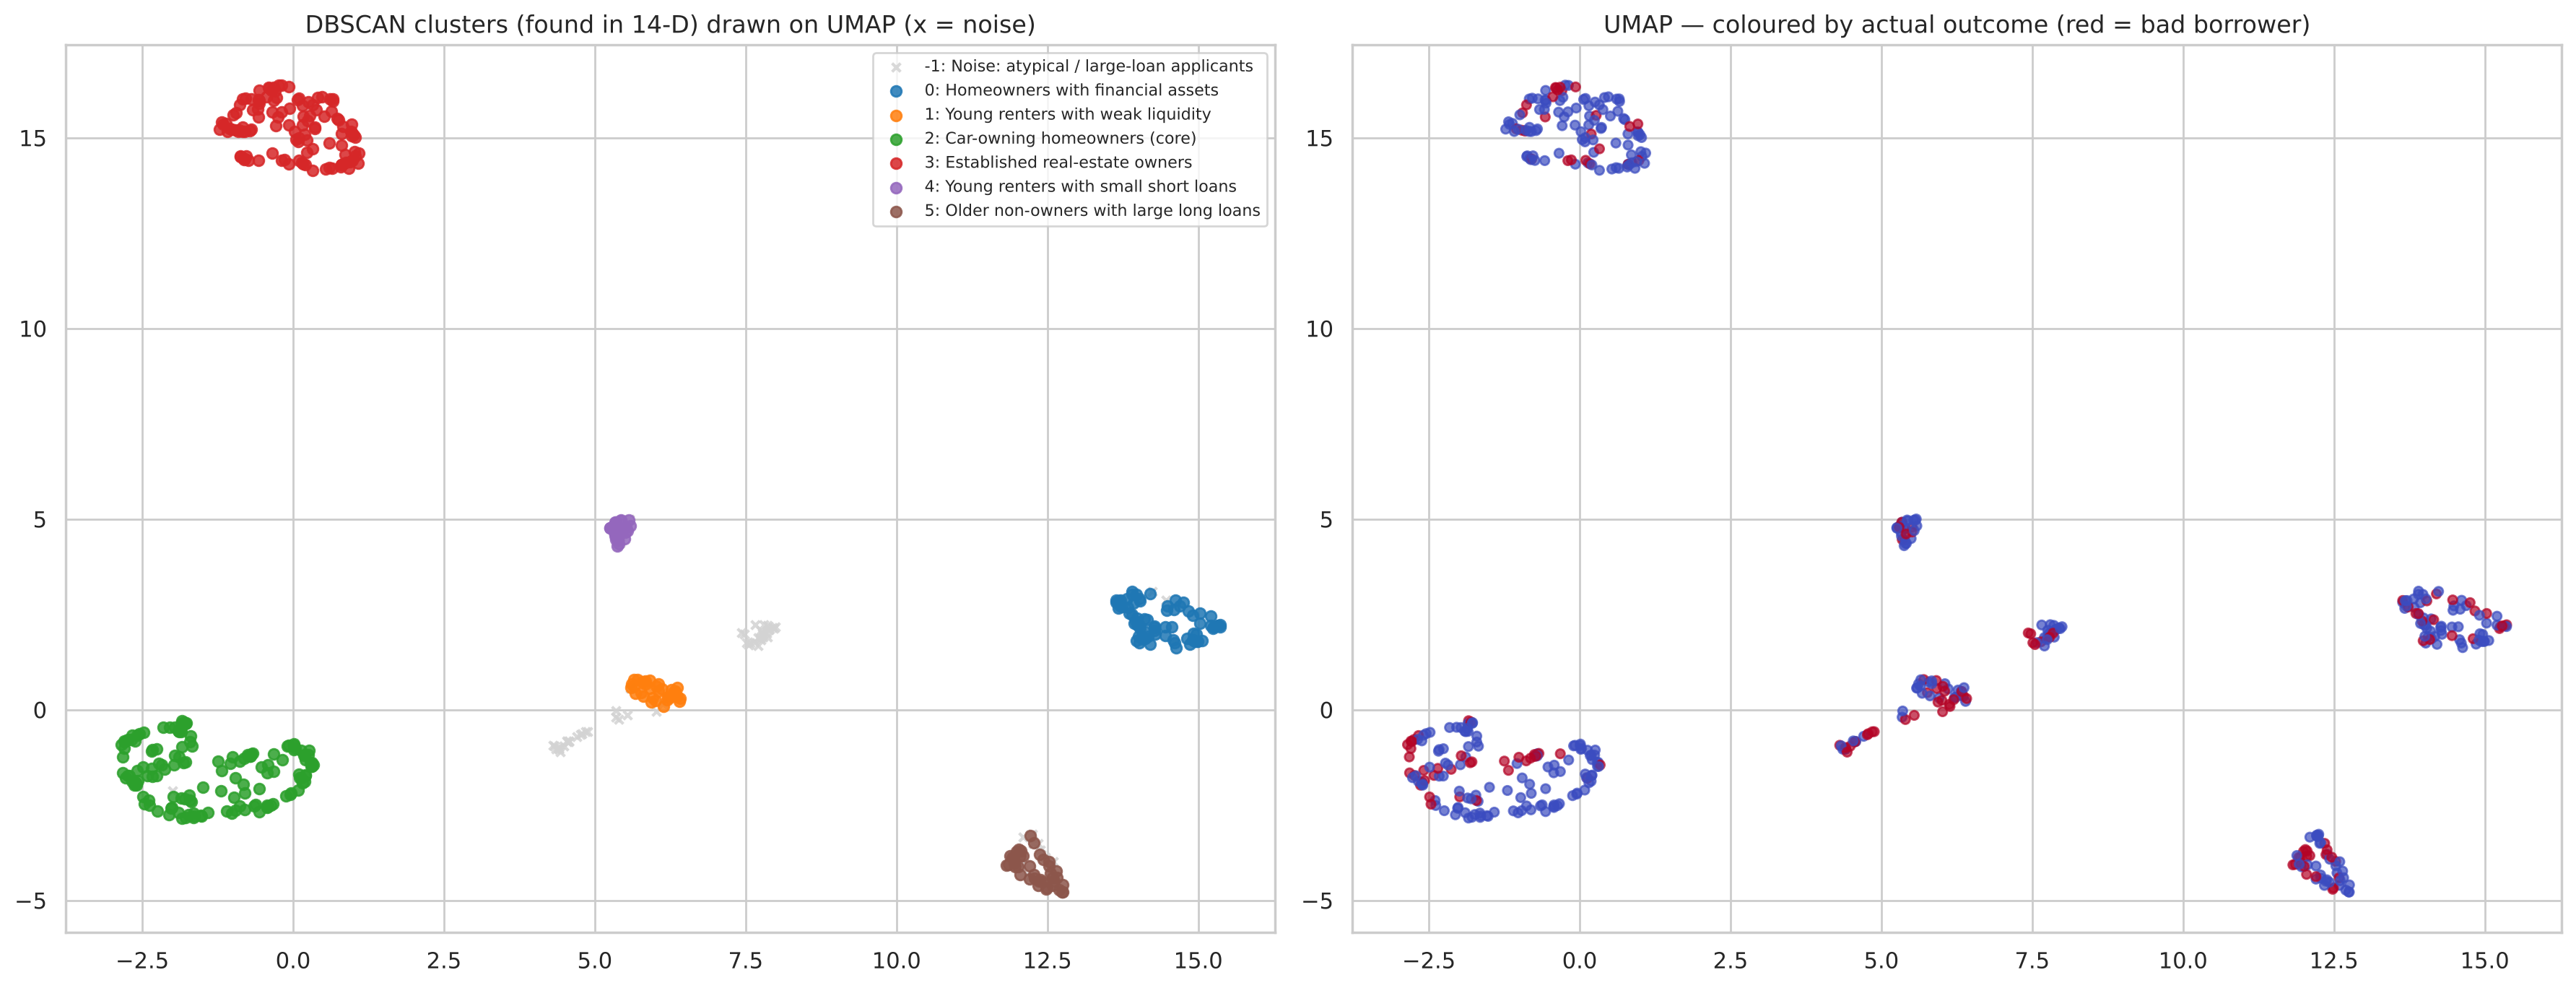

In [33]:
# DBSCAN labels already exist (section 3). UMAP is computed now, only to draw them.
reducer_vis = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=RANDOM_STATE)
U_vis = reducer_vis.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for cl in order:
    m = labels == cl
    axes[0].scatter(U_vis[m, 0], U_vis[m, 1], s=18 if cl == -1 else 28, c=[pal[cl]], marker="x" if cl == -1 else "o",
                    alpha=0.85, label=f"{cl}: {SEGMENT_NAMES[cl]}")
axes[0].set_title("DBSCAN clusters (found in 14-D) drawn on UMAP (x = noise)"); axes[0].legend(fontsize=8, loc="best")
axes[1].scatter(U_vis[:, 0], U_vis[:, 1], c=df_res["Bad"], cmap="coolwarm", s=20, alpha=0.7)
axes[1].set_title("UMAP — coloured by actual outcome (red = bad borrower)")
plt.tight_layout(); plt.show()

### 9.2 DBSCAN applied on the UMAP embedding

Settings: `n_neighbors = 15` (= `min_samples`, so both methods look at the same neighbourhood size), `min_dist = 0.0` (lets UMAP pack similar customers tightly — recommended when the embedding is used for clustering), 2 components, fixed `random_state`.
`eps` is chosen with the same procedure as before: k-distance graph + plateau rule.

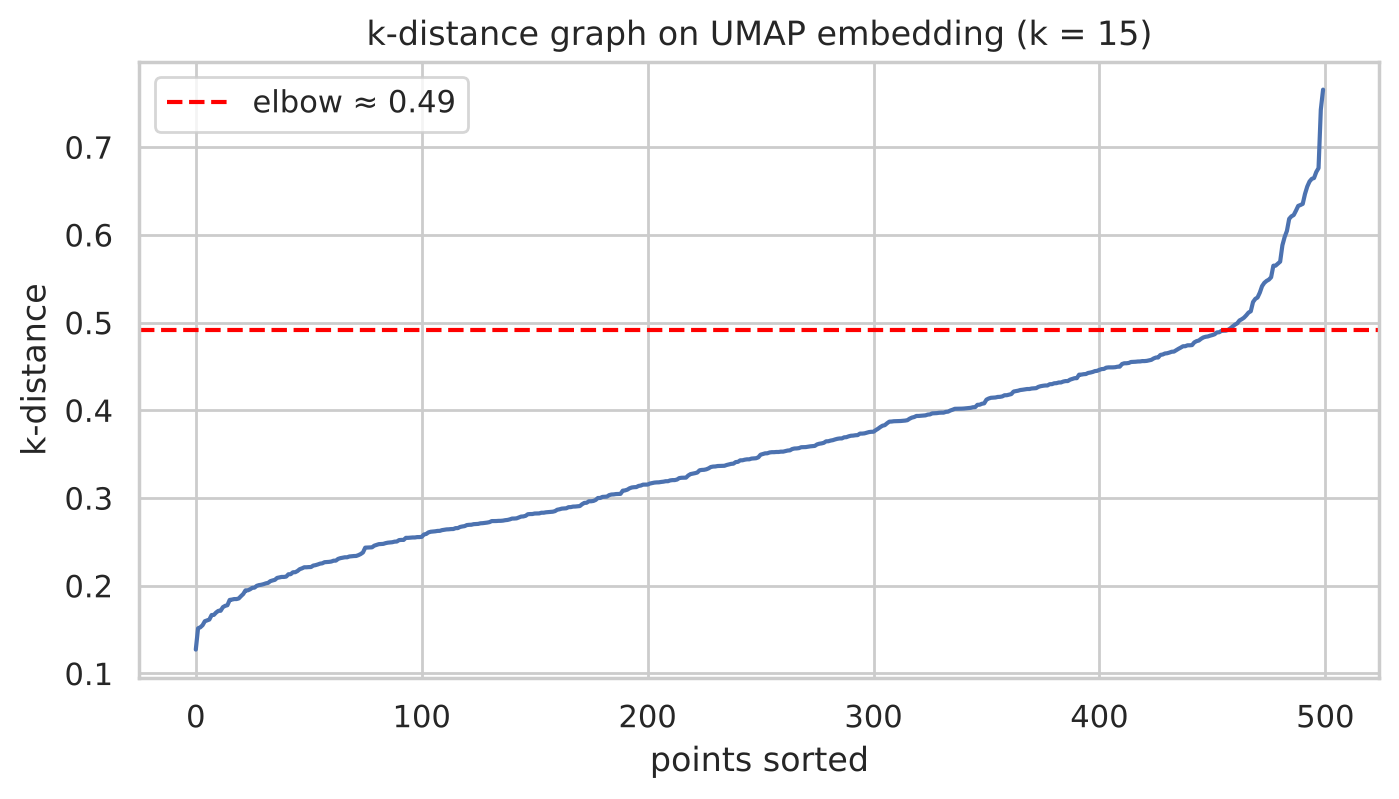

Plateau on UMAP: eps 0.5–0.9 -> 8 clusters;  optimal eps = 0.7


eps,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00,1.05,1.10,1.15,1.20,1.25,1.30,1.35,1.40,1.45,1.50
n_clusters,5.000,12.000,12.000,14.000,13.000,10.000,8.000,8.000,8.000,8.000,8.000,8.000,8.000,8.000,8.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000,7.000
noise,0.796,0.516,0.366,0.186,0.072,0.028,0.020,0.014,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
silhouette_umap,0.865,0.800,0.811,0.773,0.689,0.788,0.887,0.884,0.884,0.884,0.884,0.884,0.884,0.884,0.884,0.875,0.875,0.875,0.875,0.875,0.875,0.875,0.875,0.875,0.875,0.875,0.875


In [34]:
reducer = umap.UMAP(n_neighbors=15, min_dist=0.0, n_components=2, random_state=RANDOM_STATE)
U = reducer.fit_transform(X)                      # step 1: UMAP 14-D -> 2-D

d_u = k_distance(U, MIN_SAMPLES)
knee_u = find_knee(d_u)
plt.figure(figsize=(8, 4)); plt.plot(d_u)
plt.axhline(d_u[knee_u], ls="--", c="red", label=f"elbow ≈ {d_u[knee_u]:.2f}")
plt.title(f"k-distance graph on UMAP embedding (k = {MIN_SAMPLES})"); plt.xlabel("points sorted"); plt.ylabel("k-distance")
plt.legend(); plt.show()

rows = []
for eps in np.round(np.arange(0.20, 1.51, 0.05), 2):
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(U)   # step 2: DBSCAN on UMAP
    n, noise, sil, _ = summarize(lab, U)
    rows.append({"eps": eps, "n_clusters": n, "noise": noise, "silhouette_umap": sil})
cand_u = pd.DataFrame(rows)
ok_u = cand_u[(cand_u.n_clusters >= 2) & (cand_u.noise <= 0.15)]
n_best_u = int(ok_u.loc[ok_u.silhouette_umap.idxmax(), "n_clusters"])
plateau_u = cand_u[cand_u.n_clusters == n_best_u]
EPS_U = float(plateau_u.eps.iloc[len(plateau_u) // 2])
print(f"Plateau on UMAP: eps {plateau_u.eps.min()}–{plateau_u.eps.max()} -> {n_best_u} clusters;  optimal eps = {EPS_U}")
cand_u.round(3).set_index("eps").T

DBSCAN on UMAP: 8 clusters, noise = 0.0%, sizes = [147, 117, 75, 54, 39, 27, 24, 17]
Silhouette in UMAP space: 0.884
Silhouette of the same clusters measured in the original 14-D space: 0.264
Adjusted Rand Index vs. main DBSCAN result (section 3): 0.921


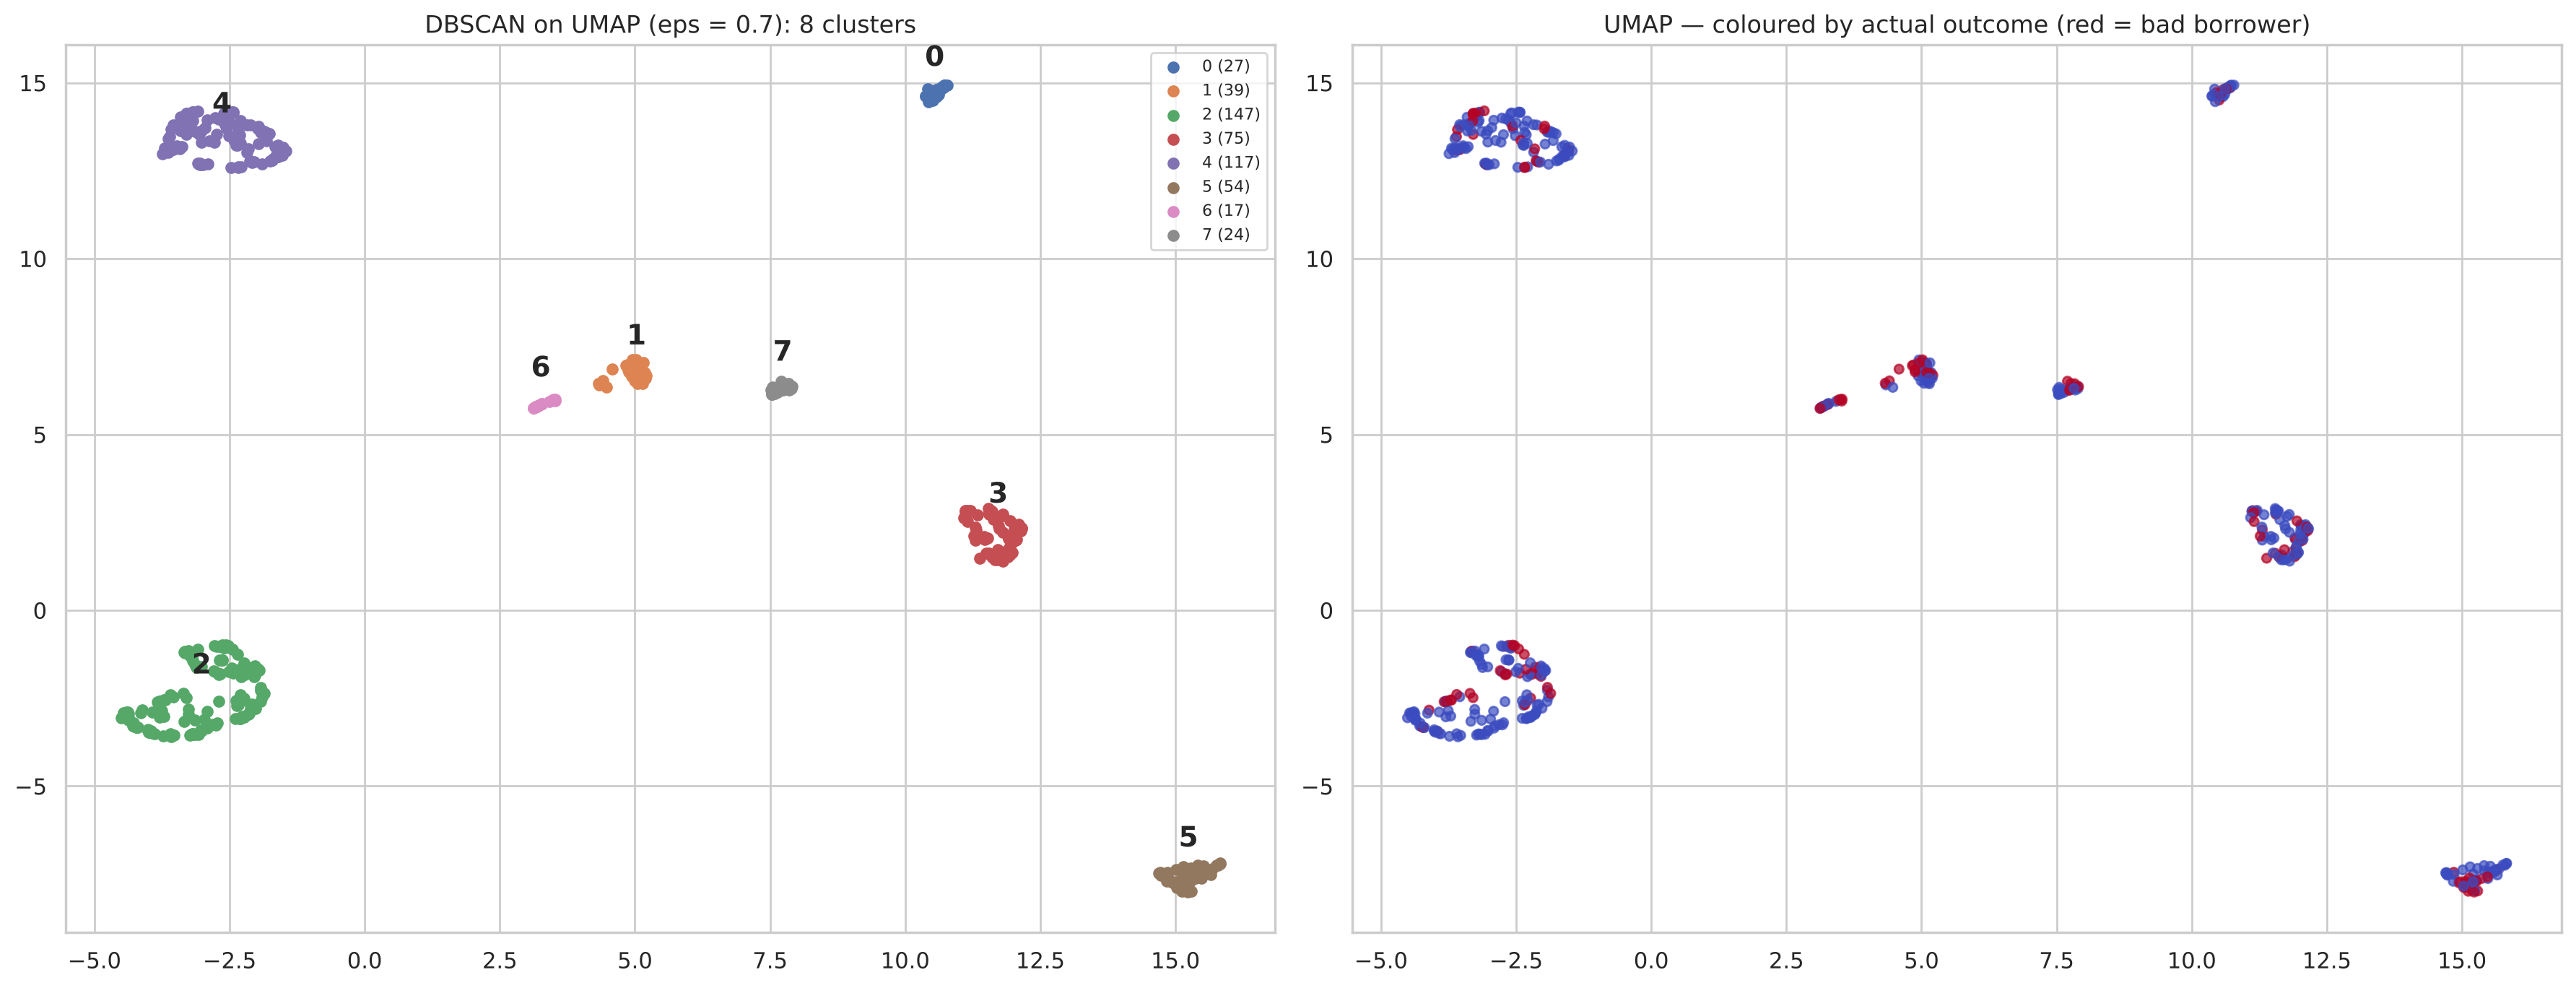

In [35]:
from sklearn.metrics import adjusted_rand_score

labels_u = DBSCAN(eps=EPS_U, min_samples=MIN_SAMPLES).fit_predict(U)
n_u, noise_u, sil_u, sizes_u = summarize(labels_u, U)
mask_u = labels_u != -1
print(f"DBSCAN on UMAP: {n_u} clusters, noise = {noise_u:.1%}, sizes = {sizes_u}")
print(f"Silhouette in UMAP space: {sil_u:.3f}")
print(f"Silhouette of the same clusters measured in the original 14-D space: {silhouette_score(X[mask_u], labels_u[mask_u]):.3f}")
print(f"Adjusted Rand Index vs. main DBSCAN result (section 3): {adjusted_rand_score(labels, labels_u):.3f}")

df_res["Cluster_UMAP"] = labels_u
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for c in sorted(set(labels_u)):
    m = labels_u == c
    axes[0].scatter(U[m, 0], U[m, 1], s=15 if c == -1 else 25, marker="x" if c == -1 else "o",
                    c="lightgrey" if c == -1 else None, label=f"{c} ({m.sum()})")
    if c != -1:
        axes[0].annotate(str(c), (np.median(U[m, 0]), np.median(U[m, 1])), xytext=(0, 14), textcoords="offset points",
                         fontsize=14, weight="bold", ha="center")
axes[0].set_title(f"DBSCAN on UMAP (eps = {EPS_U}): {n_u} clusters"); axes[0].legend(fontsize=8)
axes[1].scatter(U[:, 0], U[:, 1], c=df_res["Bad"], cmap="coolwarm", s=20, alpha=0.7)
axes[1].set_title("UMAP — coloured by actual outcome (red = bad borrower)")
plt.tight_layout(); plt.show()

In [36]:
# How do the UMAP clusters relate to the main clusters and to housing / asset?
print("Main DBSCAN cluster (rows) vs DBSCAN-on-UMAP cluster (columns):")
display(pd.crosstab(df_res["Cluster"], df_res["Cluster_UMAP"]))

prof_u = df_res.groupby("Cluster_UMAP").agg(
    customers=("Bad", "size"),
    main_asset=("Most.valuable.available.asset", mode_share),
    housing=("Type.of.apartment", mode_share),
    median_amount=("Credit.Amount", "median"),
    mean_duration=("Duration.of.Credit..month.", "mean"),
    mean_age=("Age..years.", "mean"),
    past_problems=("Payment.Status.of.Previous.Credit", lambda s: (s == 1).mean()),
    bad_rate=("Bad", "mean"))
prof_u.style.format({"median_amount": "{:,.0f}", "mean_duration": "{:.1f}", "mean_age": "{:.1f}",
                     "past_problems": "{:.0%}", "bad_rate": "{:.0%}"}).background_gradient(subset=["bad_rate"], cmap="Reds")

Main DBSCAN cluster (rows) vs DBSCAN-on-UMAP cluster (columns):


Cluster_UMAP,0,1,2,3,4,5,6,7
Cluster,,,,,,,,
-1,3,7,1,3,0,14,17,24
0,0,0,0,72,0,0,0,0
1,0,32,0,0,0,0,0,0
2,0,0,146,0,0,0,0,0
3,0,0,0,0,117,0,0,0
4,24,0,0,0,0,0,0,0
5,0,0,0,0,0,40,0,0


,customers,main_asset,housing,median_amount,mean_duration,mean_age,past_problems,bad_rate
Cluster_UMAP,,,,,,,,
0,27,1 (100%),1 (100%),"1,795",15.0,31.3,7%,22%
1,39,3 (87%),1 (100%),"3,092",24.8,28.4,18%,46%
2,147,3 (100%),2 (100%),"2,406",23.2,33.5,9%,24%
3,75,2 (100%),2 (99%),"2,171",19.5,36.3,1%,28%
4,117,1 (100%),2 (100%),"1,473",17.6,36.7,4%,21%
5,54,4 (100%),3 (100%),"4,400",28.8,44.9,11%,37%
6,17,4 (100%),2 (100%),"4,297",25.5,38.4,6%,59%
7,24,2 (100%),1 (100%),"1,778",20.3,32.0,8%,29%


### 9.3 Interpretation: DBSCAN on UMAP vs. the main DBSCAN

**Choosing `eps` on UMAP.** The k-distance graph on the UMAP embedding bends at ≈ 0.49. The grid shows a plateau for `eps` = 0.50–0.90 with **8 clusters**; its middle **`eps = 0.7`** is taken (same rule as in section 2.6). With `min_dist = 0` UMAP packs similar customers into very tight groups, so the plateau is wide and almost no point is left as noise.

**What changed compared with the main result (6 clusters + 69 noise):**

| Cluster on UMAP | Size | Profile | Bad rate | Relation to main DBSCAN |
|---|---|---|---|---|
| 4 | 117 | real estate + own home, small short loans | 21 % | = main cluster 3 |
| 2 | 147 | car + own home | 24 % | = main cluster 2 (+1 noise point) |
| 3 | 75 | savings / life insurance + own home | 28 % | = main cluster 0 (+3 noise) |
| 0 | 27 | real estate + rents, small short loans | 22 % | = main cluster 4 (+3 noise) |
| 1 | 39 | car + rents, young (28), 18 % past problems | 46 % | = main cluster 1 (+7 noise) |
| 5 | 54 | no property + lives for free, older, large long loans | 37 % | = main cluster 5 (+14 noise) |
| **6** | **17** | **no property but owns a home, large loans (median 4 297), 25.5 months** | **59 %** | **new — was noise** |
| **7** | **24** | **life insurance + rents, small loans** | **29 %** | **new — was noise** |

* **Adjusted Rand Index = 0.92** — the two partitions agree very strongly: the six main segments are found again, so the main result is **robust** to the method.
* **Advantage of UMAP + DBSCAN:** it isolates two additional small groups out of the noise. Especially **cluster 6** (17 customers, **59 % bad** — the riskiest group in the whole analysis): customers without any valuable asset who nevertheless take large, long loans. In the main model they were noise, now they form a clear high-risk niche.
* **Disadvantage:** **noise = 0 %**. UMAP pulls every point into some group, so DBSCAN loses its key advantage — detection of atypical applications (the very large, contradictory loans from section 3.1 are now hidden inside clusters).
* **Silhouette 0.88 in the UMAP space is misleading:** it is measured in the compressed 2-D picture. Measured in the original 14-D space the same clusters have silhouette **0.26**, slightly *lower* than the main model (0.29).
* UMAP depends on its parameters (`n_neighbors`, `min_dist`) and on the library version / random seed, so numbers may differ slightly on another machine.

**Why UMAP → DBSCAN is acceptable while t-SNE → DBSCAN is not:** UMAP builds a fuzzy nearest-neighbour graph and optimises a cross-entropy objective that keeps much more of the global and density structure, it is reproducible with a fixed seed, and a fitted UMAP can `transform()` new customers — so it can be a real pre-processing step (the UMAP → density clustering pipeline is used in practice). t-SNE only preserves local neighbourhoods and cannot transform new data.

**Conclusion of the experiment.** The main model (DBSCAN on the 14-D standardized data, `eps = 2.85`, `min_samples = 15`) stays the primary result: it keeps a meaningful noise group for manual review and does not depend on a stochastic embedding. DBSCAN on UMAP confirms the same six segments (ARI 0.92) and is useful as a complementary view, because it reveals the small, very risky group "no assets + large loan" (59 % bad), which deserves a separate credit rule.